In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import h5py

from pathlib import Path

from skimage.transform import resize

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers


# Reproducibility
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)


# Paths
DATA_ROOT = Path("../data/raw")
RESULTS_ROOT = Path("../results")

RESULTS_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

IMG_SIZE = 128

CLASS_NAMES = [
    "Glioma",
    "Meningioma",
    "Pituitary"
]

print("TensorFlow:", tf.__version__)
print("Image size:", IMG_SIZE)

TensorFlow: 2.21.0
Image size: 128


In [3]:
mat_files = sorted(
    p for p in DATA_ROOT.rglob("*.mat")
    if p.name.lower() != "cvind.mat"
)

print(f"MAT files found: {len(mat_files)}")

MAT files found: 3064


In [4]:
def load_figshare_data(mat_files):
    images = []
    labels = []
    patient_ids = []

    for mat_file in mat_files:

        with h5py.File(mat_file, "r") as f:

            cjdata = f["cjdata"]

            image = np.asarray(
                cjdata["image"],
                dtype=np.float32
            )

            label = int(
                np.asarray(
                    cjdata["label"]
                ).squeeze()
            )

            pid_codes = np.asarray(
                cjdata["PID"]
            ).reshape(-1)

            patient_id = "".join(
                chr(int(code))
                for code in pid_codes
            )

            images.append(image)
            labels.append(label)
            patient_ids.append(patient_id)

    return (
        images,
        np.asarray(labels, dtype=np.int64),
        np.asarray(patient_ids)
    )


images, labels, patient_ids = load_figshare_data(
    mat_files
)

print("Images:", len(images))
print("Labels:", len(labels))
print("Patients:", len(np.unique(patient_ids)))

Images: 3064
Labels: 3064
Patients: 233


In [5]:
X_images = np.empty(
    (len(images), IMG_SIZE, IMG_SIZE),
    dtype=np.float32
)

for i, image in enumerate(images):

    resized = resize(
        image,
        (IMG_SIZE, IMG_SIZE),
        anti_aliasing=True,
        preserve_range=True
    ).astype(np.float32)

    image_min = resized.min()
    image_max = resized.max()

    if image_max > image_min:
        resized = (
            resized - image_min
        ) / (
            image_max - image_min
        )
    else:
        resized = np.zeros_like(resized)

    X_images[i] = resized


y = labels.copy()

print("Input shape:", X_images.shape)
print("Label shape:", y.shape)

Input shape: (3064, 128, 128)
Label shape: (3064,)


In [6]:
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED
)

train_idx, test_idx = next(
    gss.split(
        X_images,
        y,
        groups=patient_ids
    )
)


X_train_images = X_images[train_idx]
X_test_images = X_images[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

pid_train = patient_ids[train_idx]
pid_test = patient_ids[test_idx]


print("Training samples:", len(X_train_images))
print("Testing samples :", len(X_test_images))

print(
    "Patient overlap:",
    len(
        set(pid_train) &
        set(pid_test)
    )
)

Training samples: 2452
Testing samples : 612
Patient overlap: 0


In [7]:
gss_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=SEED
)

train_inner_idx, val_idx = next(
    gss_val.split(
        X_train_images,
        y_train,
        groups=pid_train
    )
)


X_train_final = X_train_images[
    train_inner_idx
]

X_val = X_train_images[
    val_idx
]

y_train_final = y_train[
    train_inner_idx
]

y_val = y_train[
    val_idx
]


print("Train:", X_train_final.shape)
print("Validation:", X_val.shape)
print("Test:", X_test_images.shape)

Train: (2051, 128, 128)
Validation: (401, 128, 128)
Test: (612, 128, 128)


In [8]:
X_train_flat = X_train_final.reshape(
    X_train_final.shape[0],
    -1
)

X_val_flat = X_val.reshape(
    X_val.shape[0],
    -1
)

X_test_flat = X_test_images.reshape(
    X_test_images.shape[0],
    -1
)


scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train_flat
)

X_val_scaled = scaler.transform(
    X_val_flat
)

X_test_scaled = scaler.transform(
    X_test_flat
)


print("Train:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:", X_test_scaled.shape)

Train: (2051, 16384)
Validation: (401, 16384)
Test: (612, 16384)


In [9]:
y_train_ann = y_train_final - 1
y_val_ann = y_val - 1
y_test_ann = y_test - 1


classes = np.unique(y_train_ann)

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_ann
)

ann_class_weights = dict(
    zip(
        classes,
        class_weights_array
    )
)

print("Classes:", classes)
print("Class weights:", ann_class_weights)

Classes: [0 1 2]
Class weights: {0: 1.2340553549939832, 1: 0.687793427230047, 2: 1.3591782637508283}


In [10]:
ann_v2 = keras.Sequential(
    [
        keras.Input(
            shape=(X_train_scaled.shape[1],)
        ),

        layers.Dense(
            256,
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.50),

        layers.Dense(
            128,
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.40),

        layers.Dense(
            64,
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.30),

        layers.Dense(
            3,
            activation="softmax"
        )
    ],
    name="Brain_Tumor_ANN_v2"
)

ann_v2.summary()

Model: "Brain_Tumor_ANN_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │     4,194,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,237,699 (16.17 MB)

 Trainable params: 4,236,803 (16.16 MB)

 Non-trainable params: 896 (3.50 KB)

In [11]:
ann_v2.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=5e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [12]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-6,
    verbose=1
)

checkpoint = keras.callbacks.ModelCheckpoint(
    filepath=str(
        RESULTS_ROOT / "best_ann_v2.keras"
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [13]:
history_v2 = ann_v2.fit(
    X_train_scaled,
    y_train_ann,

    validation_data=(
        X_val_scaled,
        y_val_ann
    ),

    epochs=100,
    batch_size=32,

    class_weight=ann_class_weights,

    callbacks=[
        early_stopping,
        reduce_lr,
        checkpoint
    ],

    verbose=1
)

Epoch 1/100
64/65 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.5693 - loss: 0.9614
Epoch 1: val_loss improved from None to 0.53261, saving model to ..\results\best_ann_v2.keras

Epoch 1: finished saving model to ..\results\best_ann_v2.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 11s 85ms/step - accuracy: 0.5700 - loss: 0.9602 - val_accuracy: 0.8379 - val_loss: 0.5326 - learning_rate: 5.0000e-04
Epoch 2/100
64/65 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.7339 - loss: 0.6736
Epoch 2: val_loss improved from 0.53261 to 0.42145, saving model to ..\results\best_ann_v2.keras

Epoch 2: finished saving model to ..\results\best_ann_v2.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 5s 76ms/step - accuracy: 0.7343 - loss: 0.6729 - val_accuracy: 0.8753 - val_loss: 0.4215 - learning_rate: 5.0000e-04
Epoch 3/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.8064 - loss: 0.5302
Epoch 3: val_loss did not improve from 0.42145
65/65 ━━━━━━━━━━━━━━━━━━━━ 4s 57ms/step - accuracy: 0.8064 - loss: 0.5302 - val_accurac

In [14]:
best_ann_v2 = keras.models.load_model(
    RESULTS_ROOT / "best_ann_v2.keras"
)

test_prob_v2 = best_ann_v2.predict(
    X_test_scaled,
    verbose=0
)

y_pred_v2 = np.argmax(
    test_prob_v2,
    axis=1
)


ann_v2_accuracy = accuracy_score(
    y_test_ann,
    y_pred_v2
)

ann_v2_precision = precision_score(
    y_test_ann,
    y_pred_v2,
    average="macro",
    zero_division=0
)

ann_v2_recall = recall_score(
    y_test_ann,
    y_pred_v2,
    average="macro",
    zero_division=0
)

ann_v2_f1 = f1_score(
    y_test_ann,
    y_pred_v2,
    average="macro",
    zero_division=0
)


print("========== ANN-v2 RESULTS ==========")
print(f"Accuracy        : {ann_v2_accuracy:.4f}")
print(f"Macro Precision : {ann_v2_precision:.4f}")
print(f"Macro Recall    : {ann_v2_recall:.4f}")
print(f"Macro F1        : {ann_v2_f1:.4f}")

========== ANN-v2 RESULTS ==========
Accuracy        : 0.8056
Macro Precision : 0.7624
Macro Recall    : 0.7729
Macro F1        : 0.7649


In [15]:
print(
    classification_report(
        y_test_ann,
        y_pred_v2,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Glioma     0.5882    0.6122    0.6000        98
  Meningioma     0.8765    0.7639    0.8163       288
   Pituitary     0.8224    0.9425    0.8784       226

    accuracy                         0.8056       612
   macro avg     0.7624    0.7729    0.7649       612
weighted avg     0.8104    0.8056    0.8046       612



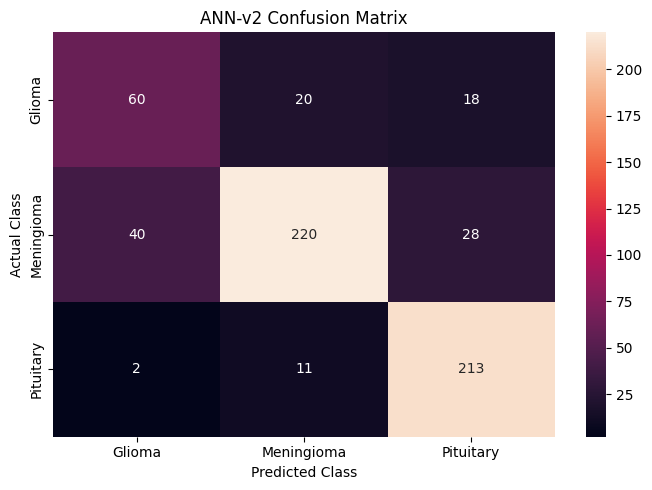

In [16]:
cm_v2 = confusion_matrix(
    y_test_ann,
    y_pred_v2
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_v2,
    annot=True,
    fmt="d",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("ANN-v2 Confusion Matrix")

plt.tight_layout()
plt.show()

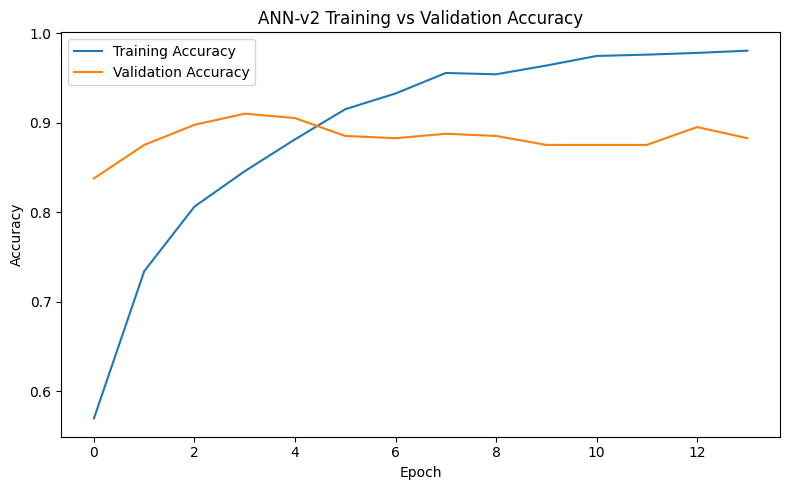

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_v2.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_v2.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title(
    "ANN-v2 Training vs Validation Accuracy"
)

plt.legend()
plt.tight_layout()
plt.show()

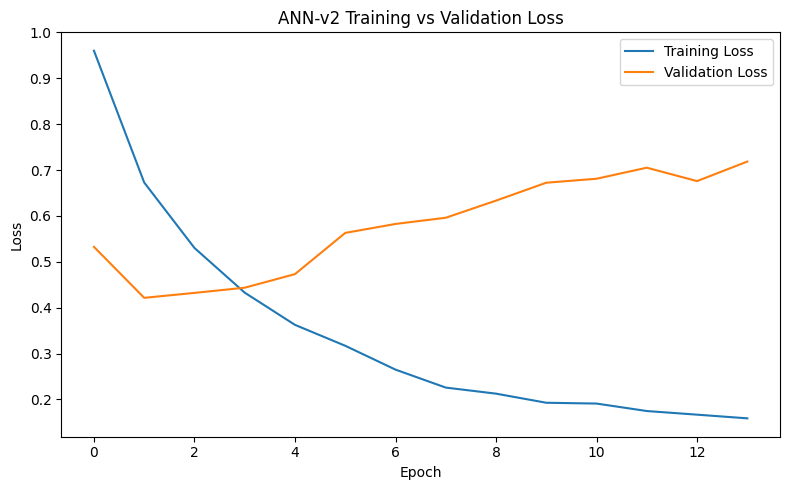

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_v2.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_v2.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(
    "ANN-v2 Training vs Validation Loss"
)

plt.legend()
plt.tight_layout()
plt.show()

In [19]:
ann_v3 = keras.Sequential(
    [
        keras.Input(
            shape=(X_train_scaled.shape[1],)
        ),

        layers.Dense(
            256,
            kernel_regularizer=regularizers.l2(5e-5)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.35),

        layers.Dense(
            128,
            kernel_regularizer=regularizers.l2(5e-5)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.25),

        layers.Dense(
            64,
            kernel_regularizer=regularizers.l2(5e-5)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.15),

        layers.Dense(
            3,
            activation="softmax"
        )
    ],
    name="Brain_Tumor_ANN_v3"
)

ann_v3.summary()

Model: "Brain_Tumor_ANN_v3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 256)            │     4,194,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,237,699 (16.17 MB)

 Trainable params: 4,236,803 (16.16 MB)

 Non-trainable params: 896 (3.50 KB)

In [20]:
ann_v3.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=3e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [21]:
early_stopping_v3 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_v3 = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=1,
    min_lr=1e-6,
    verbose=1
)

checkpoint_v3 = keras.callbacks.ModelCheckpoint(
    filepath=str(
        RESULTS_ROOT / "best_ann_v3.keras"
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [22]:
history_v3 = ann_v3.fit(
    X_train_scaled,
    y_train_ann,
    validation_data=(
        X_val_scaled,
        y_val_ann
    ),
    epochs=30,
    batch_size=32,
    class_weight=ann_class_weights,
    callbacks=[
        early_stopping_v3,
        reduce_lr_v3,
        checkpoint_v3
    ],
    verbose=1
)

Epoch 1/30
64/65 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.6567 - loss: 0.7797
Epoch 1: val_loss improved from None to 0.46404, saving model to ..\results\best_ann_v3.keras

Epoch 1: finished saving model to ..\results\best_ann_v3.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 9s 67ms/step - accuracy: 0.6572 - loss: 0.7789 - val_accuracy: 0.8379 - val_loss: 0.4640 - learning_rate: 3.0000e-04
Epoch 2/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.8216 - loss: 0.4695
Epoch 2: val_loss improved from 0.46404 to 0.45709, saving model to ..\results\best_ann_v3.keras

Epoch 2: finished saving model to ..\results\best_ann_v3.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 4s 62ms/step - accuracy: 0.8216 - loss: 0.4695 - val_accuracy: 0.8853 - val_loss: 0.4571 - learning_rate: 3.0000e-04
Epoch 3/30
64/65 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.8804 - loss: 0.3468
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.

Epoch 3: val_loss did not improve from 0.45709
65/65 ━━━━━━━━

In [23]:
best_ann_v3 = keras.models.load_model(
    RESULTS_ROOT / "best_ann_v3.keras"
)

test_prob_v3 = best_ann_v3.predict(
    X_test_scaled,
    verbose=0
)

y_pred_v3 = np.argmax(
    test_prob_v3,
    axis=1
)

In [24]:
ann_v3_accuracy = accuracy_score(
    y_test_ann,
    y_pred_v3
)

ann_v3_precision = precision_score(
    y_test_ann,
    y_pred_v3,
    average="macro",
    zero_division=0
)

ann_v3_recall = recall_score(
    y_test_ann,
    y_pred_v3,
    average="macro",
    zero_division=0
)

ann_v3_f1 = f1_score(
    y_test_ann,
    y_pred_v3,
    average="macro",
    zero_division=0
)


print("========== ANN-v3 RESULTS ==========")
print(f"Accuracy        : {ann_v3_accuracy:.4f}")
print(f"Macro Precision : {ann_v3_precision:.4f}")
print(f"Macro Recall    : {ann_v3_recall:.4f}")
print(f"Macro F1        : {ann_v3_f1:.4f}")

========== ANN-v3 RESULTS ==========
Accuracy        : 0.8366
Macro Precision : 0.8019
Macro Recall    : 0.8340
Macro F1        : 0.8128


In [25]:
print(
    classification_report(
        y_test_ann,
        y_pred_v3,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Glioma     0.6240    0.7959    0.6996        98
  Meningioma     0.9036    0.7812    0.8380       288
   Pituitary     0.8782    0.9248    0.9009       226

    accuracy                         0.8366       612
   macro avg     0.8019    0.8340    0.8128       612
weighted avg     0.8494    0.8366    0.8390       612



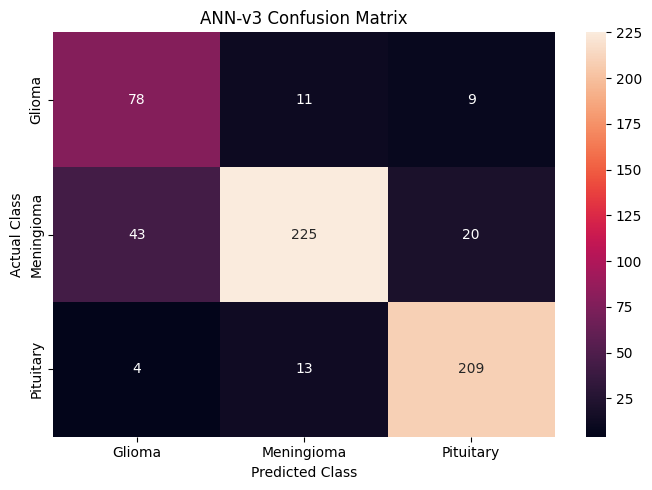

In [26]:
cm_v3 = confusion_matrix(
    y_test_ann,
    y_pred_v3
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_v3,
    annot=True,
    fmt="d",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("ANN-v3 Confusion Matrix")

plt.tight_layout()
plt.show()

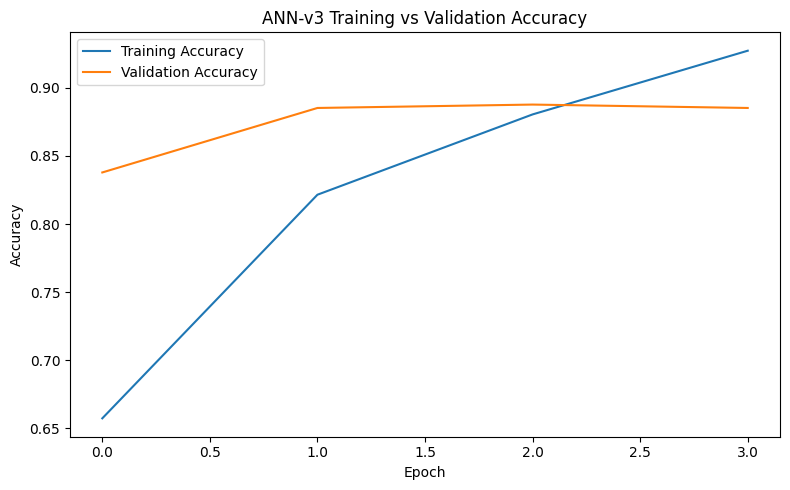

In [27]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_v3.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_v3.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ANN-v3 Training vs Validation Accuracy")

plt.legend()
plt.tight_layout()
plt.show()

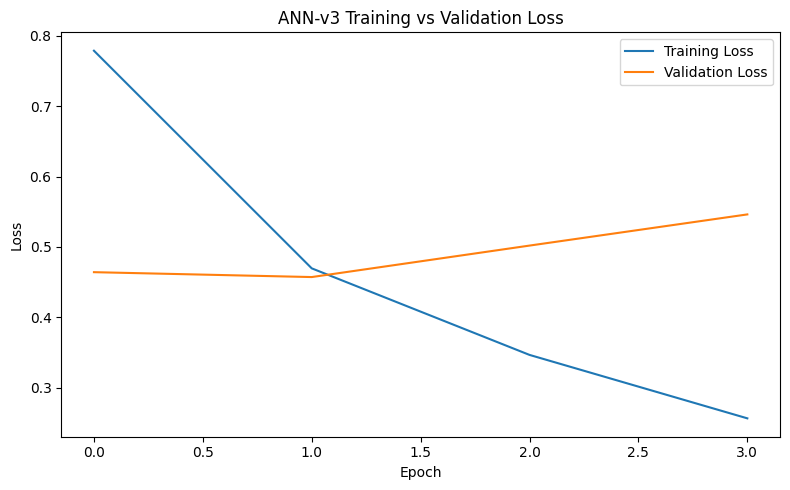

In [28]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_v3.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_v3.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN-v3 Training vs Validation Loss")

plt.legend()
plt.tight_layout()
plt.show()

In [29]:
ann_comparison = pd.DataFrame({
    "Model": [
        "ANN-v1",
        "ANN-v2",
        "ANN-v3"
    ],

    "Accuracy": [
        0.8252,
        0.8007,
        ann_v3_accuracy
    ],

    "Macro Precision": [
        0.7896,
        0.7653,
        ann_v3_precision
    ],

    "Macro Recall": [
        0.7826,
        0.7986,
        ann_v3_recall
    ],

    "Macro F1": [
        0.7839,
        0.7732,
        ann_v3_f1
    ]
})

ann_comparison

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,ANN-v1,0.825200,0.789600,0.782600,0.783900
1,ANN-v2,0.800700,0.765300,0.798600,0.773200
2,ANN-v3,0.836601,0.801922,0.833982,0.812801


In [30]:
augmentation = keras.Sequential(
    [
        layers.RandomRotation(
            factor=0.03,
            fill_mode="nearest"
        ),
        layers.RandomTranslation(
            height_factor=0.05,
            width_factor=0.05,
            fill_mode="nearest"
        )
    ],
    name="MRI_Augmentation"
)


X_train_aug = np.empty_like(X_train_final)

for i in range(len(X_train_final)):
    image = X_train_final[i][..., np.newaxis]

    augmented = augmentation(
        image,
        training=True
    ).numpy().squeeze()

    X_train_aug[i] = augmented


# Original + augmented training samples
X_train_combined = np.concatenate(
    [
        X_train_final,
        X_train_aug
    ],
    axis=0
)

y_train_combined = np.concatenate(
    [
        y_train_final,
        y_train_final
    ],
    axis=0
)

print("Original training samples :", len(X_train_final))
print("Augmented training samples:", len(X_train_aug))
print("Combined training samples :", len(X_train_combined))

Original training samples : 2051
Augmented training samples: 2051
Combined training samples : 4102


In [31]:
X_train_v4_flat = X_train_combined.reshape(
    X_train_combined.shape[0],
    -1
)

X_val_v4_flat = X_val.reshape(
    X_val.shape[0],
    -1
)

X_test_v4_flat = X_test_images.reshape(
    X_test_images.shape[0],
    -1
)


scaler_v4 = StandardScaler()

X_train_v4_scaled = scaler_v4.fit_transform(
    X_train_v4_flat
)

X_val_v4_scaled = scaler_v4.transform(
    X_val_v4_flat
)

X_test_v4_scaled = scaler_v4.transform(
    X_test_v4_flat
)


print("Train:", X_train_v4_scaled.shape)
print("Validation:", X_val_v4_scaled.shape)
print("Test:", X_test_v4_scaled.shape)

Train: (4102, 16384)
Validation: (401, 16384)
Test: (612, 16384)


In [32]:
y_train_v4 = y_train_combined - 1
y_val_v4 = y_val - 1
y_test_v4 = y_test - 1


classes_v4 = np.unique(y_train_v4)

class_weights_v4 = compute_class_weight(
    class_weight="balanced",
    classes=classes_v4,
    y=y_train_v4
)

ann_v4_class_weights = dict(
    zip(
        classes_v4,
        class_weights_v4
    )
)

print("Class weights:", ann_v4_class_weights)

Class weights: {0: 1.2340553549939832, 1: 0.687793427230047, 2: 1.3591782637508283}


In [33]:
ann_v4 = keras.Sequential(
    [
        keras.Input(
            shape=(X_train_v4_scaled.shape[1],)
        ),

        layers.Dense(
            128,
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.30),

        layers.Dense(
            64,
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.25),

        layers.Dense(
            32,
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.Activation("relu"),
        layers.Dropout(0.15),

        layers.Dense(
            3,
            activation="softmax"
        )
    ],
    name="Brain_Tumor_ANN_v4"
)

ann_v4.summary()

Model: "Brain_Tumor_ANN_v4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,108,483 (8.04 MB)

 Trainable params: 2,108,099 (8.04 MB)

 Non-trainable params: 384 (1.50 KB)

In [34]:
ann_v4.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=3e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [35]:
early_stopping_v4 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_v4 = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

checkpoint_v4 = keras.callbacks.ModelCheckpoint(
    filepath=str(
        RESULTS_ROOT / "best_ann_v4.keras"
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [36]:
history_v4 = ann_v4.fit(
    X_train_v4_scaled,
    y_train_v4,

    validation_data=(
        X_val_v4_scaled,
        y_val_v4
    ),

    epochs=40,
    batch_size=32,

    class_weight=ann_v4_class_weights,

    callbacks=[
        early_stopping_v4,
        reduce_lr_v4,
        checkpoint_v4
    ],

    verbose=1
)

Epoch 1/40
128/129 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.6594 - loss: 0.7734
Epoch 1: val_loss improved from None to 0.41723, saving model to ..\results\best_ann_v4.keras

Epoch 1: finished saving model to ..\results\best_ann_v4.keras
129/129 ━━━━━━━━━━━━━━━━━━━━ 8s 32ms/step - accuracy: 0.6597 - loss: 0.7728 - val_accuracy: 0.8653 - val_loss: 0.4172 - learning_rate: 3.0000e-04
Epoch 2/40
128/129 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.7524 - loss: 0.5713
Epoch 2: val_loss improved from 0.41723 to 0.37850, saving model to ..\results\best_ann_v4.keras

Epoch 2: finished saving model to ..\results\best_ann_v4.keras
129/129 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - accuracy: 0.7526 - loss: 0.5710 - val_accuracy: 0.8828 - val_loss: 0.3785 - learning_rate: 3.0000e-04
Epoch 3/40
127/129 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.8073 - loss: 0.4835
Epoch 3: val_loss improved from 0.37850 to 0.34887, saving model to ..\results\best_ann_v4.keras

Epoch 3: finished saving model

In [37]:
history_v4 = ann_v4.fit(
    X_train_v4_scaled,
    y_train_v4,

    validation_data=(
        X_val_v4_scaled,
        y_val_v4
    ),

    epochs=40,
    batch_size=32,

    class_weight=ann_v4_class_weights,

    callbacks=[
        early_stopping_v4,
        reduce_lr_v4,
        checkpoint_v4
    ],

    verbose=1
)

Epoch 1/40
128/129 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.8557 - loss: 0.3957
Epoch 1: val_loss did not improve from 0.34887
129/129 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.8557 - loss: 0.3955 - val_accuracy: 0.8728 - val_loss: 0.3510 - learning_rate: 7.5000e-05
Epoch 2/40
128/129 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.8635 - loss: 0.3669
Epoch 2: val_loss did not improve from 0.34887
129/129 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.8635 - loss: 0.3667 - val_accuracy: 0.8828 - val_loss: 0.3531 - learning_rate: 7.5000e-05
Epoch 3/40
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.8810 - loss: 0.3284
Epoch 3: ReduceLROnPlateau reducing learning rate to 3.7500001781154424e-05.

Epoch 3: val_loss did not improve from 0.34887
129/129 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.8810 - loss: 0.3284 - val_accuracy: 0.8653 - val_loss: 0.3747 - learning_rate: 7.5000e-05
Epoch 4/40
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9025 - loss: 0.

In [38]:
best_ann_v4 = keras.models.load_model(
    RESULTS_ROOT / "best_ann_v4.keras"
)

test_prob_v4 = best_ann_v4.predict(
    X_test_v4_scaled,
    verbose=0
)

y_pred_v4 = np.argmax(
    test_prob_v4,
    axis=1
)

In [39]:
ann_v4_accuracy = accuracy_score(
    y_test_v4,
    y_pred_v4
)

ann_v4_precision = precision_score(
    y_test_v4,
    y_pred_v4,
    average="macro",
    zero_division=0
)

ann_v4_recall = recall_score(
    y_test_v4,
    y_pred_v4,
    average="macro",
    zero_division=0
)

ann_v4_f1 = f1_score(
    y_test_v4,
    y_pred_v4,
    average="macro",
    zero_division=0
)


print("========== ANN-v4 RESULTS ==========")
print(f"Accuracy        : {ann_v4_accuracy:.4f}")
print(f"Macro Precision : {ann_v4_precision:.4f}")
print(f"Macro Recall    : {ann_v4_recall:.4f}")
print(f"Macro F1        : {ann_v4_f1:.4f}")

========== ANN-v4 RESULTS ==========
Accuracy        : 0.8350
Macro Precision : 0.7922
Macro Recall    : 0.8123
Macro F1        : 0.7994


In [40]:
print(
    classification_report(
        y_test_v4,
        y_pred_v4,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Glioma     0.5656    0.7041    0.6273        98
  Meningioma     0.8699    0.8125    0.8402       288
   Pituitary     0.9412    0.9204    0.9306       226

    accuracy                         0.8350       612
   macro avg     0.7922    0.8123    0.7994       612
weighted avg     0.8475    0.8350    0.8395       612



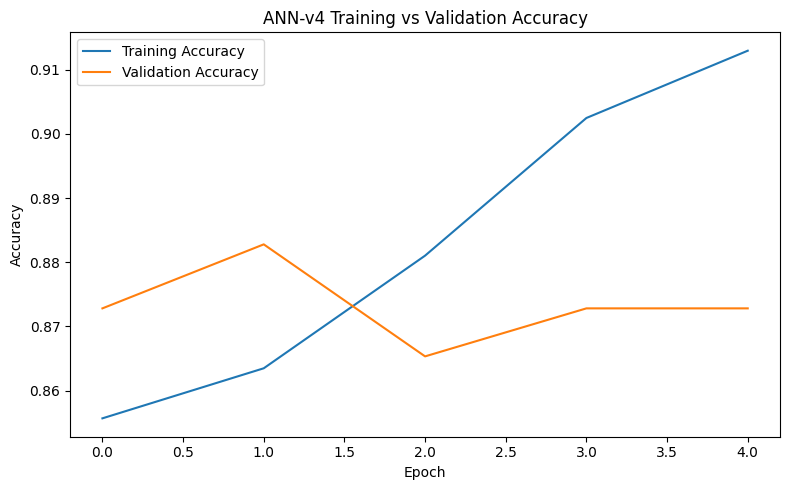

In [41]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_v4.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_v4.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ANN-v4 Training vs Validation Accuracy")

plt.legend()
plt.tight_layout()
plt.show()

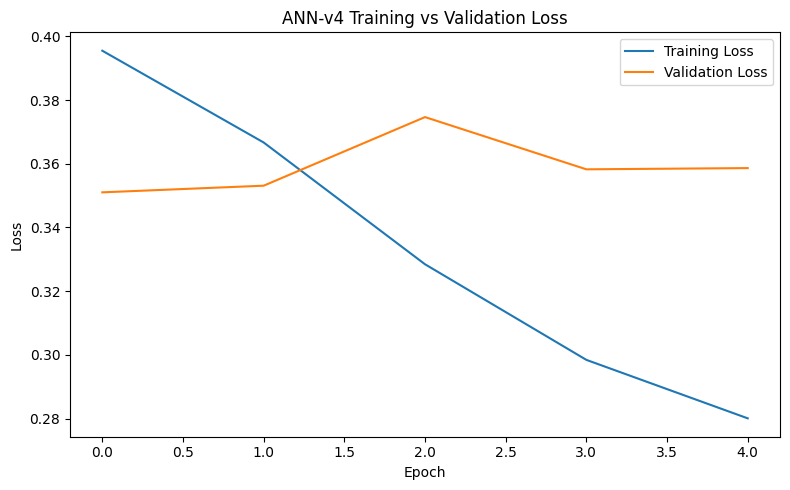

In [42]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_v4.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_v4.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN-v4 Training vs Validation Loss")

plt.legend()
plt.tight_layout()
plt.show()

In [43]:
print("========== ANN-v4 RESULTS ==========")
print(f"Accuracy        : {ann_v4_accuracy:.4f}")
print(f"Macro Precision : {ann_v4_precision:.4f}")
print(f"Macro Recall    : {ann_v4_recall:.4f}")
print(f"Macro F1        : {ann_v4_f1:.4f}")

========== ANN-v4 RESULTS ==========
Accuracy        : 0.8350
Macro Precision : 0.7922
Macro Recall    : 0.8123
Macro F1        : 0.7994


In [44]:
## seeing this annv3 is good 
## Now cnn implenataion starts from here


In [45]:
# ============================================================
# ANN HYPERPARAMETER TUNING
# Fixed: Architecture, L2, BatchNorm, Optimizer, Batch Size
# Varied: Dropout Rates and Learning Rate
# ============================================================

ann_experiments = [
    {
        "name": "ANN-Exp1",
        "dropout": [0.20, 0.20, 0.20],
        "learning_rate": 1e-3
    },
    {
        "name": "ANN-Exp2",
        "dropout": [0.30, 0.30, 0.30],
        "learning_rate": 1e-3
    },
    {
        "name": "ANN-Exp3",
        "dropout": [0.40, 0.40, 0.40],
        "learning_rate": 1e-3
    },
    {
        "name": "ANN-Exp4",
        "dropout": [0.20, 0.20, 0.20],
        "learning_rate": 5e-4
    },
    {
        "name": "ANN-Exp5",
        "dropout": [0.30, 0.30, 0.30],
        "learning_rate": 5e-4
    },
    {
        "name": "ANN-Exp6",
        "dropout": [0.40, 0.40, 0.40],
        "learning_rate": 5e-4
    },
    {
        "name": "ANN-Exp7",
        "dropout": [0.35, 0.25, 0.15],
        "learning_rate": 3e-4
    }
]

print("Total experiments:", len(ann_experiments))

Total experiments: 7


In [46]:
def build_ann_experiment(dropout_rates, learning_rate):

    model = keras.Sequential(
        [
            keras.Input(
                shape=(X_train_scaled.shape[1],)
            ),

            layers.Dense(
                256,
                kernel_regularizer=regularizers.l2(5e-5)
            ),
            layers.BatchNormalization(),
            layers.Activation("relu"),
            layers.Dropout(dropout_rates[0]),

            layers.Dense(
                128,
                kernel_regularizer=regularizers.l2(5e-5)
            ),
            layers.BatchNormalization(),
            layers.Activation("relu"),
            layers.Dropout(dropout_rates[1]),

            layers.Dense(
                64,
                kernel_regularizer=regularizers.l2(5e-5)
            ),
            layers.BatchNormalization(),
            layers.Activation("relu"),
            layers.Dropout(dropout_rates[2]),

            layers.Dense(
                3,
                activation="softmax"
            )
        ],
        name="ANN_Hyperparameter_Model"
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [47]:
# ============================================================
# TRAIN AND EVALUATE ALL ANN CONFIGURATIONS
# ============================================================

ann_results = []

for exp in ann_experiments:

    print("\n" + "=" * 60)
    print(f"Running {exp['name']}")
    print(f"Dropout      : {exp['dropout']}")
    print(f"Learning Rate: {exp['learning_rate']}")
    print("=" * 60)

    model = build_ann_experiment(
        dropout_rates=exp["dropout"],
        learning_rate=exp["learning_rate"]
    )

    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=0
    )

    reduce_lr = keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=0
    )

    history = model.fit(
        X_train_scaled,
        y_train_ann,
        validation_data=(
            X_val_scaled,
            y_val_ann
        ),
        epochs=50,
        batch_size=32,
        class_weight=ann_class_weights,
        callbacks=[
            early_stopping,
            reduce_lr
        ],
        verbose=0
    )

    test_prob = model.predict(
        X_test_scaled,
        verbose=0
    )

    y_pred = np.argmax(
        test_prob,
        axis=1
    )

    accuracy = accuracy_score(
        y_test_ann,
        y_pred
    )

    precision = precision_score(
        y_test_ann,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test_ann,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test_ann,
        y_pred,
        average="macro",
        zero_division=0
    )

    ann_results.append(
        {
            "Model": exp["name"],
            "Dropout": str(exp["dropout"]),
            "Learning Rate": exp["learning_rate"],
            "Best Val Accuracy": max(
                history.history["val_accuracy"]
            ),
            "Best Val Loss": min(
                history.history["val_loss"]
            ),
            "Test Accuracy": accuracy,
            "Macro Precision": precision,
            "Macro Recall": recall,
            "Macro F1": f1
        }
    )

    print(f"Test Accuracy : {accuracy:.4f}")
    print(f"Macro Precision: {precision:.4f}")
    print(f"Macro Recall   : {recall:.4f}")
    print(f"Macro F1       : {f1:.4f}")


Running ANN-Exp1
Dropout      : [0.2, 0.2, 0.2]
Learning Rate: 0.001
Test Accuracy : 0.8513
Macro Precision: 0.8110
Macro Recall   : 0.8091
Macro F1       : 0.8098

Running ANN-Exp2
Dropout      : [0.3, 0.3, 0.3]
Learning Rate: 0.001
Test Accuracy : 0.8170
Macro Precision: 0.7859
Macro Recall   : 0.8288
Macro F1       : 0.7926

Running ANN-Exp3
Dropout      : [0.4, 0.4, 0.4]
Learning Rate: 0.001
Test Accuracy : 0.7908
Macro Precision: 0.7527
Macro Recall   : 0.7858
Macro F1       : 0.7578

Running ANN-Exp4
Dropout      : [0.2, 0.2, 0.2]
Learning Rate: 0.0005
Test Accuracy : 0.8121
Macro Precision: 0.7679
Macro Recall   : 0.7736
Macro F1       : 0.7681

Running ANN-Exp5
Dropout      : [0.3, 0.3, 0.3]
Learning Rate: 0.0005
Test Accuracy : 0.8382
Macro Precision: 0.7998
Macro Recall   : 0.8153
Macro F1       : 0.8063

Running ANN-Exp6
Dropout      : [0.4, 0.4, 0.4]
Learning Rate: 0.0005
Test Accuracy : 0.8023
Macro Precision: 0.7700
Macro Recall   : 0.8100
Macro F1       : 0.7786

Runnin

In [48]:
# ============================================================
# ANN EXPERIMENT COMPARISON
# ============================================================

ann_results_df = pd.DataFrame(
    ann_results
)

ann_results_df = ann_results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

ann_results_df

,Model,Dropout,Learning Rate,Best Val Accuracy,Best Val Loss,Test Accuracy,Macro Precision,Macro Recall,Macro F1
0,ANN-Exp1,"[0.2, 0.2, 0.2]",0.0010,0.912718,0.367666,0.851307,0.811025,0.809131,0.809810
1,ANN-Exp5,"[0.3, 0.3, 0.3]",0.0005,0.895262,0.383767,0.838235,0.799754,0.815262,0.806334
2,ANN-Exp2,"[0.3, 0.3, 0.3]",0.0010,0.910224,0.487356,0.816993,0.785912,0.828752,0.792594
3,ANN-Exp6,"[0.4, 0.4, 0.4]",0.0005,0.900249,0.399475,0.802288,0.770049,0.809994,0.778576
4,ANN-Exp4,"[0.2, 0.2, 0.2]",0.0005,0.905237,0.435847,0.812092,0.767861,0.773647,0.768132
5,ANN-Exp7,"[0.35, 0.25, 0.15]",0.0003,0.902743,0.372895,0.800654,0.754941,0.772912,0.759210
6,ANN-Exp3,"[0.4, 0.4, 0.4]",0.0010,0.885287,0.383320,0.790850,0.752669,0.785846,0.757800


In [49]:
best_ann = ann_results_df.iloc[0]

print("=" * 50)
print("BEST ANN CONFIGURATION")
print("=" * 50)

print(f"Model           : {best_ann['Model']}")
print(f"Dropout         : {best_ann['Dropout']}")
print(f"Learning Rate   : {best_ann['Learning Rate']}")
print(f"Test Accuracy   : {best_ann['Test Accuracy']:.4f}")
print(f"Macro Precision : {best_ann['Macro Precision']:.4f}")
print(f"Macro Recall    : {best_ann['Macro Recall']:.4f}")
print(f"Macro F1        : {best_ann['Macro F1']:.4f}")

BEST ANN CONFIGURATION
Model           : ANN-Exp1
Dropout         : [0.2, 0.2, 0.2]
Learning Rate   : 0.001
Test Accuracy   : 0.8513
Macro Precision : 0.8110
Macro Recall    : 0.8091
Macro F1        : 0.8098


In [50]:
X_train_cnn = X_train_final[..., np.newaxis]
X_val_cnn = X_val[..., np.newaxis]
X_test_cnn = X_test_images[..., np.newaxis]

y_train_cnn = y_train_final - 1
y_val_cnn = y_val - 1
y_test_cnn = y_test - 1

print("Training:", X_train_cnn.shape)
print("Validation:", X_val_cnn.shape)
print("Test:", X_test_cnn.shape)

Training: (2051, 128, 128, 1)
Validation: (401, 128, 128, 1)
Test: (612, 128, 128, 1)


In [51]:
from sklearn.utils.class_weight import compute_class_weight

classes_cnn = np.unique(y_train_cnn)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes_cnn,
    y=y_train_cnn
)

cnn_class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(
        classes_cnn,
        class_weights
    )
}

print("CNN Class Weights")
print("-" * 30)

for class_id, weight in cnn_class_weights.items():
    print(f"Class {class_id}: {weight:.4f}")

CNN Class Weights
------------------------------
Class 0: 1.2341
Class 1: 0.6878
Class 2: 1.3592


In [52]:
# ============================================================
# MRI DATA AUGMENTATION
# ============================================================

cnn_augmentation = keras.Sequential(
    [
        layers.RandomRotation(
            factor=0.03,
            fill_mode="nearest"
        ),
        layers.RandomTranslation(
            height_factor=0.05,
            width_factor=0.05,
            fill_mode="nearest"
        ),
        layers.RandomZoom(
            height_factor=0.05,
            width_factor=0.05,
            fill_mode="nearest"
        )
    ],
    name="MRI_Augmentation"
)

In [53]:
# ============================================================
# CNN-V1 ARCHITECTURE
# ============================================================

cnn_model = keras.Sequential(
    [
        keras.Input(
            shape=(128, 128, 1)
        ),

        cnn_augmentation,

        # -------------------------
        # Convolution Block 1
        # -------------------------
        layers.Conv2D(
            32,
            kernel_size=3,
            padding="same",
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.Conv2D(
            32,
            kernel_size=3,
            padding="same",
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.MaxPooling2D(
            pool_size=2
        ),

        layers.Dropout(0.20),

        # -------------------------
        # Convolution Block 2
        # -------------------------
        layers.Conv2D(
            64,
            kernel_size=3,
            padding="same",
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.Conv2D(
            64,
            kernel_size=3,
            padding="same",
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.MaxPooling2D(
            pool_size=2
        ),

        layers.Dropout(0.25),

        # -------------------------
        # Convolution Block 3
        # -------------------------
        layers.Conv2D(
            128,
            kernel_size=3,
            padding="same",
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.Conv2D(
            128,
            kernel_size=3,
            padding="same",
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.MaxPooling2D(
            pool_size=2
        ),

        layers.Dropout(0.30),

        # -------------------------
        # Feature Aggregation
        # -------------------------
        layers.GlobalAveragePooling2D(),

        layers.Dense(
            128,
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.Dropout(0.40),

        # -------------------------
        # Output
        # -------------------------
        layers.Dense(
            3,
            activation="softmax"
        )
    ],
    name="Brain_Tumor_CNN"
)

cnn_model.summary()

Model: "Brain_Tumor_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ MRI_Augmentation (Sequential)   │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_29          │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_30 (Activation)      │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_30          │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_31 (Activation)      │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30 (Dropout)            │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_31          │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_32 (Activation)      │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_32          │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_33 (Activation)      │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_31 (Dropout)            │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_33          │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_34 (Activation)      │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_34          │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 305,635 (1.17 MB)

 Trainable params: 304,483 (1.16 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [54]:
cnn_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=3e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [55]:
# ============================================================
# CNN TRAINING CALLBACKS
# ============================================================

early_stopping_cnn = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_cnn = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

checkpoint_cnn = keras.callbacks.ModelCheckpoint(
    filepath=str(
        RESULTS_ROOT / "best_cnn_model.keras"
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [56]:
# ============================================================
# CNN TRAINING
# ============================================================

history_cnn = cnn_model.fit(
    X_train_cnn,
    y_train_cnn,
    validation_data=(
        X_val_cnn,
        y_val_cnn
    ),
    epochs=50,
    batch_size=32,
    class_weight=cnn_class_weights,
    callbacks=[
        early_stopping_cnn,
        reduce_lr_cnn,
        checkpoint_cnn
    ],
    verbose=1
)

Epoch 1/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5929 - loss: 0.9270
Epoch 1: val_loss improved from None to 1.16161, saving model to ..\results\best_cnn_model.keras

Epoch 1: finished saving model to ..\results\best_cnn_model.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 105s 1s/step - accuracy: 0.5929 - loss: 0.9270 - val_accuracy: 0.4663 - val_loss: 1.1616 - learning_rate: 3.0000e-04
Epoch 2/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6626 - loss: 0.7856
Epoch 2: val_loss did not improve from 1.16161
65/65 ━━━━━━━━━━━━━━━━━━━━ 95s 1s/step - accuracy: 0.6626 - loss: 0.7856 - val_accuracy: 0.1397 - val_loss: 1.3053 - learning_rate: 3.0000e-04
Epoch 3/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6992 - loss: 0.6912
Epoch 3: val_loss did not improve from 1.16161
65/65 ━━━━━━━━━━━━━━━━━━━━ 85s 1s/step - accuracy: 0.6992 - loss: 0.6912 - val_accuracy: 0.3591 - val_loss: 1.2521 - learning_rate: 3.0000e-04
Epoch 4/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.

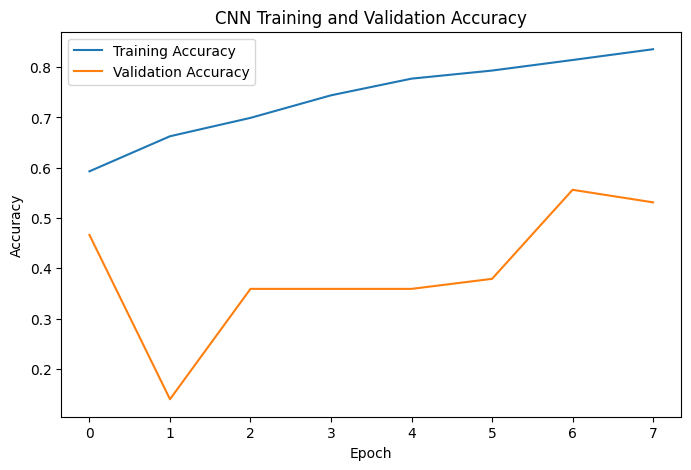

In [57]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history_cnn.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_cnn.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.legend()
plt.show()

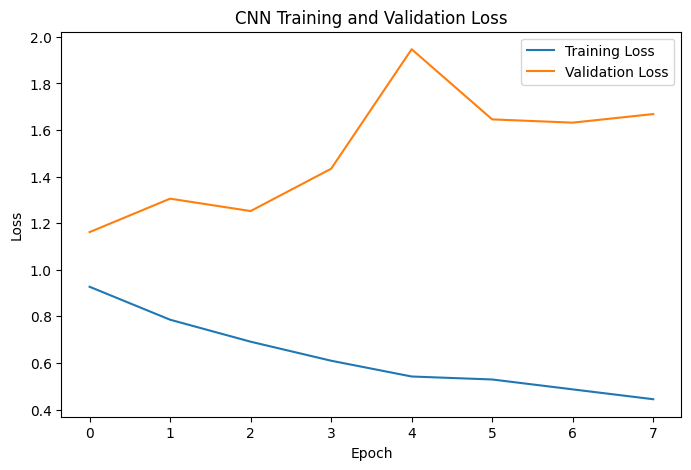

In [58]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_cnn.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_cnn.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()
plt.show()

In [59]:
# ============================================================
# CNN TEST EVALUATION
# ============================================================

best_cnn = keras.models.load_model(
    RESULTS_ROOT / "best_cnn_model.keras"
)

test_prob_cnn = best_cnn.predict(
    X_test_cnn,
    verbose=0
)

y_pred_cnn = np.argmax(
    test_prob_cnn,
    axis=1
)

In [60]:
cnn_accuracy = accuracy_score(
    y_test_cnn,
    y_pred_cnn
)

cnn_precision = precision_score(
    y_test_cnn,
    y_pred_cnn,
    average="macro",
    zero_division=0
)

cnn_recall = recall_score(
    y_test_cnn,
    y_pred_cnn,
    average="macro",
    zero_division=0
)

cnn_f1 = f1_score(
    y_test_cnn,
    y_pred_cnn,
    average="macro",
    zero_division=0
)

print("========== CNN RESULTS ==========")

print(f"Accuracy        : {cnn_accuracy:.4f}")
print(f"Macro Precision : {cnn_precision:.4f}")
print(f"Macro Recall    : {cnn_recall:.4f}")
print(f"Macro F1        : {cnn_f1:.4f}")

========== CNN RESULTS ==========
Accuracy        : 0.3824
Macro Precision : 0.3086
Macro Recall    : 0.4973
Macro F1        : 0.3414


In [61]:
print(
    classification_report(
        y_test_cnn,
        y_pred_cnn,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.1980    0.8061    0.3179        98
           1     0.0000    0.0000    0.0000       288
           2     0.7277    0.6858    0.7062       226

    accuracy                         0.3824       612
   macro avg     0.3086    0.4973    0.3414       612
weighted avg     0.3004    0.3824    0.3117       612



c:\Users\Vishal\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Vishal\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Vishal\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [62]:
print("Train:", np.unique(y_train_cnn, return_counts=True))
print("Val  :", np.unique(y_val_cnn, return_counts=True))
print("Test :", np.unique(y_test_cnn, return_counts=True))

Train: (array([0, 1, 2], dtype=int64), array([554, 994, 503], dtype=int64))
Val  : (array([0, 1, 2], dtype=int64), array([ 56, 144, 201], dtype=int64))
Test : (array([0, 1, 2], dtype=int64), array([ 98, 288, 226], dtype=int64))


In [63]:
print(cnn_class_weights)

{0: 1.2340553549939832, 1: 0.687793427230047, 2: 1.3591782637508283}


In [64]:
print(
    "Predictions:",
    np.unique(y_pred_cnn, return_counts=True)
)

Predictions: (array([0, 2], dtype=int64), array([399, 213], dtype=int64))


In [65]:
print("Training accuracy:")
print(history_cnn.history["accuracy"])

print("\nValidation accuracy:")
print(history_cnn.history["val_accuracy"])

print("\nTraining loss:")
print(history_cnn.history["loss"])

print("\nValidation loss:")
print(history_cnn.history["val_loss"])

Training accuracy:
[0.5928815007209778, 0.6626036167144775, 0.6991711258888245, 0.744027316570282, 0.77718186378479, 0.7932716012001038, 0.8142369389533997, 0.835689902305603]

Validation accuracy:
[0.46633416414260864, 0.1396508663892746, 0.3591022491455078, 0.3591022491455078, 0.3591022491455078, 0.37905237078666687, 0.5561097264289856, 0.5311720967292786]

Training loss:
[0.9270429611206055, 0.7855756282806396, 0.691228985786438, 0.6095048189163208, 0.5417942404747009, 0.5289978384971619, 0.48654723167419434, 0.44425442814826965]

Validation loss:
[1.1616076231002808, 1.3052533864974976, 1.2520912885665894, 1.433674693107605, 1.9468058347702026, 1.6455693244934082, 1.6316111087799072, 1.668434977531433]


In [66]:
print("Final learning rate:")

print(
    float(
        cnn_model.optimizer.learning_rate.numpy()
    )
)

Final learning rate:
7.500000356230885e-05


In [67]:
print("First 10 prediction probabilities:")

print(
    test_prob_cnn[:10]
)

First 10 prediction probabilities:
[[0.3613506  0.26483774 0.37381163]
 [0.36254108 0.26471296 0.372746  ]
 [0.36008433 0.26469663 0.37521902]
 [0.36167774 0.2646627  0.37365958]
 [0.36302826 0.2645226  0.37244913]
 [0.36272207 0.26466015 0.37261772]
 [0.36328232 0.26457492 0.37214273]
 [0.36980456 0.2649721  0.36522335]
 [0.36860693 0.26493508 0.36645803]
 [0.35999724 0.26494846 0.3750543 ]]


In [68]:
print("Current model evaluation:")
cnn_current_prob = cnn_model.predict(
    X_test_cnn,
    verbose=0
)

cnn_current_pred = np.argmax(cnn_current_prob, axis=1)

print(
    np.unique(
        cnn_current_pred,
        return_counts=True
    )
)

print("\nCheckpoint model evaluation:")

best_cnn = keras.models.load_model(
    RESULTS_ROOT / "best_cnn_model.keras"
)

cnn_best_prob = best_cnn.predict(
    X_test_cnn,
    verbose=0
)

cnn_best_pred = np.argmax(cnn_best_prob, axis=1)

print(
    np.unique(
        cnn_best_pred,
        return_counts=True
    )
)

Current model evaluation:


(array([0, 2], dtype=int64), array([399, 213], dtype=int64))

Checkpoint model evaluation:
(array([0, 2], dtype=int64), array([399, 213], dtype=int64))


In [69]:
print("Current model evaluation:")
cnn_current_prob = cnn_model.predict(
    X_test_cnn,
    verbose=0
)

cnn_current_pred = np.argmax(cnn_current_prob, axis=1)

print(
    np.unique(
        cnn_current_pred,
        return_counts=True
    )
)

print("\nCheckpoint model evaluation:")

best_cnn = keras.models.load_model(
    RESULTS_ROOT / "best_cnn_model.keras"
)

cnn_best_prob = best_cnn.predict(
    X_test_cnn,
    verbose=0
)

cnn_best_pred = np.argmax(cnn_best_prob, axis=1)

print(
    np.unique(
        cnn_best_pred,
        return_counts=True
    )
)

Current model evaluation:
(array([0, 2], dtype=int64), array([399, 213], dtype=int64))

Checkpoint model evaluation:
(array([0, 2], dtype=int64), array([399, 213], dtype=int64))


In [70]:
cnn_v2 = keras.Sequential(
    [
        keras.Input(shape=(128, 128, 1)),

        cnn_augmentation,

        # Block 1
        layers.Conv2D(
            32, 3, padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(2),
        layers.Dropout(0.15),

        # Block 2
        layers.Conv2D(
            64, 3, padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(
            64, 3, padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(2),
        layers.Dropout(0.20),

        # Block 3
        layers.Conv2D(
            128, 3, padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(2),
        layers.Dropout(0.25),

        # Feature aggregation
        layers.GlobalAveragePooling2D(),

        layers.Dense(128),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.30),

        layers.Dense(
            3,
            activation="softmax"
        )
    ],
    name="Brain_Tumor_CNN_v2"
)

In [71]:
cnn_v2.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [72]:
early_stopping_cnn_v2 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_cnn_v2 = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

checkpoint_cnn_v2 = keras.callbacks.ModelCheckpoint(
    filepath=str(
        RESULTS_ROOT / "best_cnn_v2.keras"
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [73]:
history_cnn_v2 = cnn_v2.fit(
    X_train_cnn,
    y_train_cnn,
    validation_data=(
        X_val_cnn,
        y_val_cnn
    ),
    epochs=50,
    batch_size=32,
    class_weight=cnn_class_weights,
    callbacks=[
        early_stopping_cnn_v2,
        reduce_lr_cnn_v2,
        checkpoint_cnn_v2
    ],
    verbose=1
)


Epoch 1/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 728ms/step - accuracy: 0.5627 - loss: 0.9333
Epoch 1: val_loss improved from None to 1.06658, saving model to ..\results\best_cnn_v2.keras

Epoch 1: finished saving model to ..\results\best_cnn_v2.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 59s 770ms/step - accuracy: 0.5627 - loss: 0.9333 - val_accuracy: 0.3591 - val_loss: 1.0666 - learning_rate: 1.0000e-04
Epoch 2/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 705ms/step - accuracy: 0.6070 - loss: 0.8202
Epoch 2: val_loss did not improve from 1.06658
65/65 ━━━━━━━━━━━━━━━━━━━━ 48s 734ms/step - accuracy: 0.6070 - loss: 0.8202 - val_accuracy: 0.3591 - val_loss: 1.1197 - learning_rate: 1.0000e-04
Epoch 3/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 709ms/step - accuracy: 0.6329 - loss: 0.7701
Epoch 3: val_loss did not improve from 1.06658
65/65 ━━━━━━━━━━━━━━━━━━━━ 48s 738ms/step - accuracy: 0.6329 - loss: 0.7701 - val_accuracy: 0.3591 - val_loss: 1.2374 - learning_rate: 1.0000e-04
Epoch 4/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 729ms/step 

In [74]:
best_cnn_v2 = keras.models.load_model(
    RESULTS_ROOT / "best_cnn_v2.keras"
)

test_prob_cnn_v2 = best_cnn_v2.predict(
    X_test_cnn,
    verbose=0
)

y_pred_cnn_v2 = np.argmax(
    test_prob_cnn_v2,
    axis=1
)

print(
    np.unique(
        y_pred_cnn_v2,
        return_counts=True
    )
)

(array([1, 2], dtype=int64), array([421, 191], dtype=int64))


In [75]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("CNN-v2 Classification Report:\n")

print(
    classification_report(
        y_test_cnn,
        y_pred_cnn_v2,
        target_names=[
            "Class 0",
            "Class 1",
            "Class 2"
        ],
        digits=4
    )
)

print("Accuracy:",
      accuracy_score(y_test_cnn, y_pred_cnn_v2))

print("Macro Precision:",
      precision_score(
          y_test_cnn,
          y_pred_cnn_v2,
          average="macro"
      ))

print("Macro Recall:",
      recall_score(
          y_test_cnn,
          y_pred_cnn_v2,
          average="macro"
      ))

print("Macro F1:",
      f1_score(
          y_test_cnn,
          y_pred_cnn_v2,
          average="macro"
      ))

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test_cnn,
        y_pred_cnn_v2
    )
)

CNN-v2 Classification Report:

              precision    recall  f1-score   support

     Class 0     0.0000    0.0000    0.0000        98
     Class 1     0.6580    0.9618    0.7814       288
     Class 2     0.9215    0.7788    0.8441       226

    accuracy                         0.7402       612
   macro avg     0.5265    0.5802    0.5418       612
weighted avg     0.6499    0.7402    0.6794       612

Accuracy: 0.7401960784313726
Macro Precision: 0.5264744044139897
Macro Recall: 0.5801888725008194
Macro F1: 0.5418356429102135

Confusion Matrix:
[[  0  94   4]
 [  0 277  11]
 [  0  50 176]]


c:\Users\Vishal\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Vishal\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Vishal\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Vishal\anaconda3

In [76]:
print("Original labels:", np.unique(labels))

for original_label, class_name in zip(
    [1, 2, 3],
    ["Glioma", "Meningioma", "Pituitary"]
):
    print(original_label, "->", class_name)

Original labels: [1 2 3]
1 -> Glioma
2 -> Meningioma
3 -> Pituitary


In [77]:
print("CNN labels:")
print("0 -> original label 1")
print("1 -> original label 2")
print("2 -> original label 3")

CNN labels:
0 -> original label 1
1 -> original label 2
2 -> original label 3


In [78]:
cnn_v3 = keras.Sequential(
    [
        keras.Input(shape=(128, 128, 1)),

        cnn_augmentation,

        # Block 1
        layers.Conv2D(
            32,
            kernel_size=3,
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.Conv2D(
            32,
            kernel_size=3,
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.MaxPooling2D(pool_size=2),
        layers.Dropout(0.15),

        # Block 2
        layers.Conv2D(
            64,
            kernel_size=3,
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.Conv2D(
            64,
            kernel_size=3,
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.MaxPooling2D(pool_size=2),
        layers.Dropout(0.20),

        # Block 3
        layers.Conv2D(
            128,
            kernel_size=3,
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.Conv2D(
            128,
            kernel_size=3,
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.MaxPooling2D(pool_size=2),
        layers.Dropout(0.25),

        # Block 4
        layers.Conv2D(
            256,
            kernel_size=3,
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.MaxPooling2D(pool_size=2),
        layers.Dropout(0.25),

        # Feature aggregation
        layers.GlobalAveragePooling2D(),

        layers.Dense(128),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.30),

        # Output
        layers.Dense(
            3,
            activation="softmax"
        )
    ],
    name="Brain_Tumor_CNN_v3"
)

In [79]:
cnn_v3.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [80]:
early_stopping_cnn_v3 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_cnn_v3 = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

checkpoint_cnn_v3 = keras.callbacks.ModelCheckpoint(
    filepath=str(
        RESULTS_ROOT / "best_cnn_v3.keras"
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [81]:
history_cnn_v3 = cnn_v3.fit(
    X_train_cnn,
    y_train_cnn,
    validation_data=(
        X_val_cnn,
        y_val_cnn
    ),
    epochs=50,
    batch_size=32,
    class_weight=cnn_class_weights,
    callbacks=[
        early_stopping_cnn_v3,
        reduce_lr_cnn_v3,
        checkpoint_cnn_v3
    ],
    verbose=1
)

Epoch 1/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5841 - loss: 0.9410
Epoch 1: val_loss improved from None to 1.24008, saving model to ..\results\best_cnn_v3.keras

Epoch 1: finished saving model to ..\results\best_cnn_v3.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 89s 1s/step - accuracy: 0.5841 - loss: 0.9410 - val_accuracy: 0.3591 - val_loss: 1.2401 - learning_rate: 1.0000e-04
Epoch 2/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6431 - loss: 0.7879
Epoch 2: val_loss did not improve from 1.24008
65/65 ━━━━━━━━━━━━━━━━━━━━ 82s 1s/step - accuracy: 0.6431 - loss: 0.7879 - val_accuracy: 0.3591 - val_loss: 1.3436 - learning_rate: 1.0000e-04
Epoch 3/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6743 - loss: 0.7147
Epoch 3: val_loss improved from 1.24008 to 1.20246, saving model to ..\results\best_cnn_v3.keras

Epoch 3: finished saving model to ..\results\best_cnn_v3.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 84s 1s/step - accuracy: 0.6743 - loss: 0.7147 - val_accuracy: 0.3591 - v

In [82]:
best_cnn_v3 = keras.models.load_model(
    RESULTS_ROOT / "best_cnn_v3.keras"
)

test_prob_cnn_v3 = best_cnn_v3.predict(
    X_test_cnn,
    verbose=0
)

y_pred_cnn_v3 = np.argmax(
    test_prob_cnn_v3,
    axis=1
)

print(
    "Prediction distribution:",
    np.unique(
        y_pred_cnn_v3,
        return_counts=True
    )
)

Prediction distribution: (array([1, 2], dtype=int64), array([230, 382], dtype=int64))


In [83]:
print("Train pixel statistics:")
print("Min:", X_train_cnn.min())
print("Max:", X_train_cnn.max())
print("Mean:", X_train_cnn.mean())
print("Std:", X_train_cnn.std())

print("\nValidation pixel statistics:")
print("Min:", X_val_cnn.min())
print("Max:", X_val_cnn.max())
print("Mean:", X_val_cnn.mean())
print("Std:", X_val_cnn.std())

print("\nTest pixel statistics:")
print("Min:", X_test_cnn.min())
print("Max:", X_test_cnn.max())
print("Mean:", X_test_cnn.mean())
print("Std:", X_test_cnn.std())

Train pixel statistics:
Min: 0.0
Max: 1.0
Mean: 0.18868329
Std: 0.19725342

Validation pixel statistics:
Min: 0.0
Max: 1.0
Mean: 0.19971013
Std: 0.19670263

Test pixel statistics:
Min: 0.0
Max: 1.0
Mean: 0.19466703
Std: 0.19543687


In [84]:
print("Individual image statistics:")

for i in range(5):
    img = X_train_cnn[i]

    print(
        f"Image {i}: "
        f"min={img.min():.4f}, "
        f"max={img.max():.4f}, "
        f"mean={img.mean():.4f}, "
        f"std={img.std():.4f}"
    )

Individual image statistics:
Image 0: min=0.0000, max=1.0000, mean=0.2571, std=0.1961
Image 1: min=0.0000, max=1.0000, mean=0.2553, std=0.1936
Image 2: min=0.0000, max=1.0000, mean=0.2609, std=0.1948
Image 3: min=0.0000, max=1.0000, mean=0.2214, std=0.1638
Image 4: min=0.0000, max=1.0000, mean=0.2284, std=0.1677


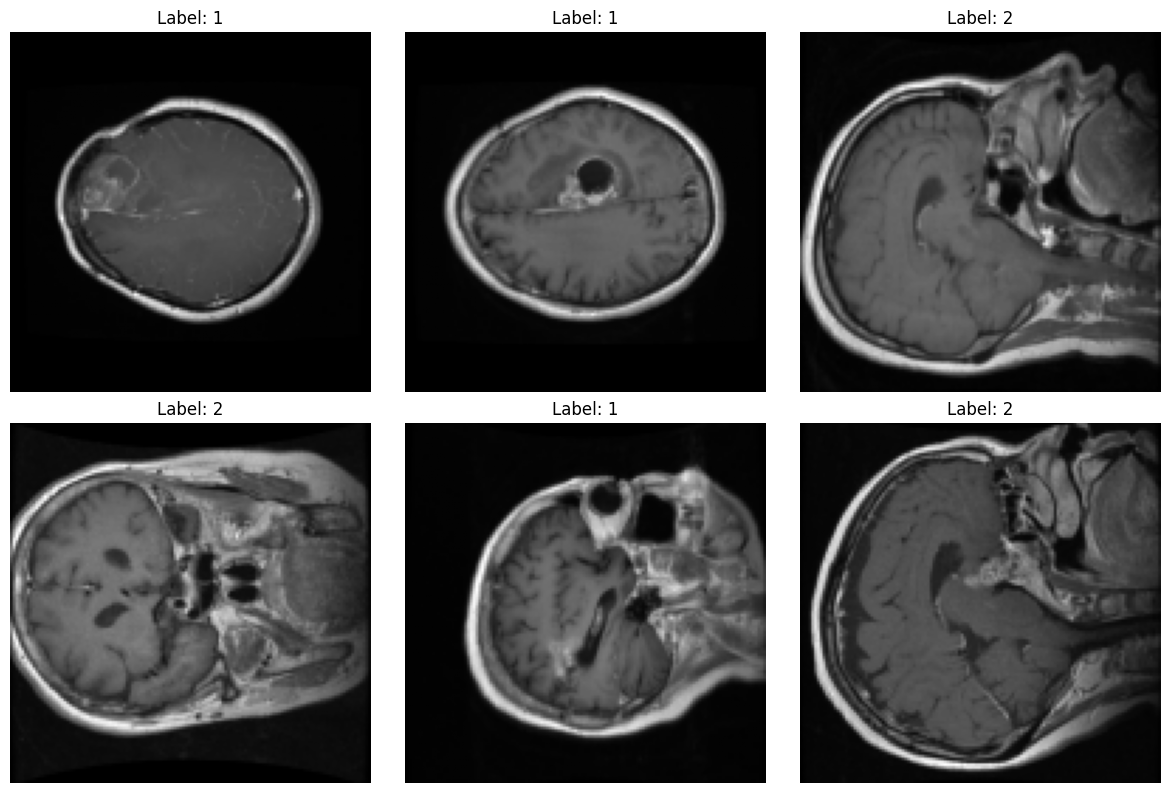

In [85]:
import matplotlib.pyplot as plt
import numpy as np

indices = np.random.choice(
    len(X_train_cnn),
    size=6,
    replace=False
)

plt.figure(figsize=(12, 8))

for i, idx in enumerate(indices):
    plt.subplot(2, 3, i + 1)
    plt.imshow(
        X_train_cnn[idx].squeeze(),
        cmap="gray"
    )
    plt.title(f"Label: {y_train_cnn[idx]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

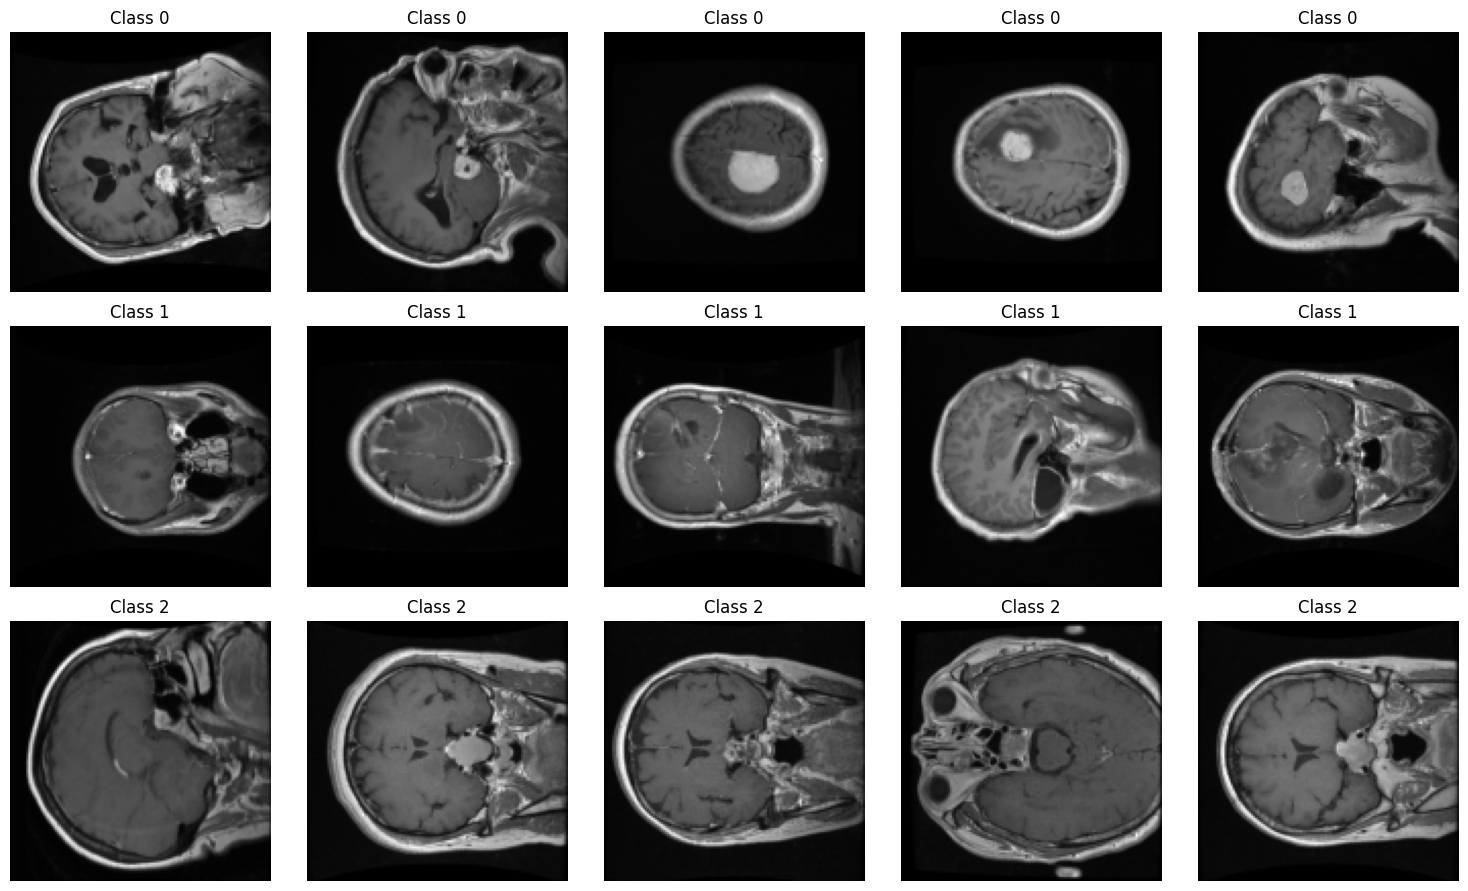

In [86]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(3, 5, figsize=(15, 9))

for class_id in [0, 1, 2]:

    class_indices = np.where(
        y_train_cnn == class_id
    )[0]

    selected = np.random.choice(
        class_indices,
        size=5,
        replace=False
    )

    for j, idx in enumerate(selected):

        axes[class_id, j].imshow(
            X_train_cnn[idx].squeeze(),
            cmap="gray"
        )

        axes[class_id, j].set_title(
            f"Class {class_id}"
        )

        axes[class_id, j].axis("off")

plt.tight_layout()
plt.show()

In [87]:
# Transfer Learning CNN
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Convert grayscale MRI to 3-channel RGB-like format
X_train_tl = np.repeat(
    X_train_cnn,
    3,
    axis=-1
)

X_val_tl = np.repeat(
    X_val_cnn,
    3,
    axis=-1
)

X_test_tl = np.repeat(
    X_test_cnn,
    3,
    axis=-1
)

print("Train:", X_train_tl.shape)
print("Validation:", X_val_tl.shape)
print("Test:", X_test_tl.shape)

Train: (2051, 128, 128, 3)
Validation: (401, 128, 128, 3)
Test: (612, 128, 128, 3)


In [88]:
tl_augmentation = keras.Sequential(
    [
        layers.RandomRotation(
            factor=0.03,
            fill_mode="nearest"
        ),
        layers.RandomTranslation(
            height_factor=0.04,
            width_factor=0.04,
            fill_mode="nearest"
        ),
        layers.RandomZoom(
            height_factor=0.05,
            width_factor=0.05,
            fill_mode="nearest"
        )
    ],
    name="MRI_TL_Augmentation"
)

In [89]:
base_model = keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(128, 128, 3)
)

base_model.trainable = False

print("Total backbone layers:", len(base_model.layers))

Total backbone layers: 238


In [90]:
inputs = keras.Input(
    shape=(128, 128, 3)
)

x = tl_augmentation(inputs)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(128)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.Dropout(0.30)(x)

outputs = layers.Dense(
    3,
    activation="softmax"
)(x)

cnn_tl = keras.Model(
    inputs,
    outputs,
    name="Brain_Tumor_EfficientNetB0"
)

cnn_tl.summary()

Model: "Brain_Tumor_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_16 (InputLayer)     │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MRI_TL_Augmentation             │ (None, 128, 128, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 4, 4, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_49          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_50 (Activation)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_43 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,438 (16.08 MB)

 Trainable params: 164,611 (643.01 KB)

 Non-trainable params: 4,049,827 (15.45 MB)

In [91]:
cnn_tl.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [92]:
early_stopping_tl = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_tl = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

checkpoint_tl = keras.callbacks.ModelCheckpoint(
    filepath=str(
        RESULTS_ROOT / "best_cnn_transfer_learning.keras"
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [93]:
history_tl = cnn_tl.fit(
    X_train_tl,
    y_train_cnn,

    validation_data=(
        X_val_tl,
        y_val_cnn
    ),

    epochs=25,
    batch_size=32,

    class_weight=cnn_class_weights,

    callbacks=[
        early_stopping_tl,
        reduce_lr_tl,
        checkpoint_tl
    ],

    verbose=1
)

Epoch 1/25
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 209ms/step - accuracy: 0.3155 - loss: 1.2253
Epoch 1: val_loss improved from None to 1.10280, saving model to ..\results\best_cnn_transfer_learning.keras

Epoch 1: finished saving model to ..\results\best_cnn_transfer_learning.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 29s 295ms/step - accuracy: 0.3155 - loss: 1.2253 - val_accuracy: 0.5012 - val_loss: 1.1028 - learning_rate: 1.0000e-04
Epoch 2/25
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 216ms/step - accuracy: 0.3272 - loss: 1.1901
Epoch 2: val_loss improved from 1.10280 to 1.07619, saving model to ..\results\best_cnn_transfer_learning.keras

Epoch 2: finished saving model to ..\results\best_cnn_transfer_learning.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 17s 268ms/step - accuracy: 0.3272 - loss: 1.1901 - val_accuracy: 0.4564 - val_loss: 1.0762 - learning_rate: 1.0000e-04
Epoch 3/25
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step - accuracy: 0.3486 - loss: 1.1552
Epoch 3: val_loss did not improve from 1.07619
65/65 ━━━━━━━━━━━━━━━━━━

In [94]:
from pathlib import Path
import keras
import numpy as np
best_cnn_tl = keras.models.load_model(
    RESULTS_ROOT / "best_cnn_transfer_learning.keras"
)

test_prob_tl = best_cnn_tl.predict(
    X_test_tl,
    verbose=0
)

y_pred_tl = np.argmax(
    test_prob_tl,
    axis=1
)

print(
    "Prediction distribution:",
    np.unique(
        y_pred_tl,
        return_counts=True
    )
)


Prediction distribution: (array([1, 2], dtype=int64), array([401, 211], dtype=int64))


In [95]:
#Le net
# ============================================================
# LE-NET | PROFESSIONAL CNN IMPLEMENTATION
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

SEED = 42

np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

IMG_SIZE = 128
NUM_CLASSES = 3
BATCH_SIZE = 32
EPOCHS = 50

print("TensorFlow version:", tf.__version__)
print("Image size:", IMG_SIZE)
print("Number of classes:", NUM_CLASSES)
print("Batch size:", BATCH_SIZE)

TensorFlow version: 2.21.0
Image size: 128
Number of classes: 3
Batch size: 32


In [96]:
# ============================================================
# DATA VERIFICATION
# ============================================================

print("Train images :", X_train_cnn.shape)
print("Validation   :", X_val_cnn.shape)
print("Test images  :", X_test_cnn.shape)

print()

print("Train labels :", y_train_cnn.shape)
print("Validation   :", y_val_cnn.shape)
print("Test labels  :", y_test_cnn.shape)

print()

print("Train classes:",
      np.unique(y_train_cnn, return_counts=True))

print("Validation classes:",
      np.unique(y_val_cnn, return_counts=True))

print("Test classes:",
      np.unique(y_test_cnn, return_counts=True))

Train images : (2051, 128, 128, 1)
Validation   : (401, 128, 128, 1)
Test images  : (612, 128, 128, 1)

Train labels : (2051,)
Validation   : (401,)
Test labels  : (612,)

Train classes: (array([0, 1, 2], dtype=int64), array([554, 994, 503], dtype=int64))
Validation classes: (array([0, 1, 2], dtype=int64), array([ 56, 144, 201], dtype=int64))
Test classes: (array([0, 1, 2], dtype=int64), array([ 98, 288, 226], dtype=int64))


In [97]:
# ============================================================
# IMAGE FORMAT STANDARDIZATION
# ============================================================

def ensure_rgb(X):

    X = np.asarray(X, dtype=np.float32)

    # Grayscale: (N, H, W)
    if X.ndim == 3:
        X = np.expand_dims(X, axis=-1)

    # Grayscale → 3 channels
    if X.shape[-1] == 1:
        X = np.repeat(X, 3, axis=-1)

    return X


X_train_lenet = ensure_rgb(X_train_cnn)
X_val_lenet   = ensure_rgb(X_val_cnn)
X_test_lenet  = ensure_rgb(X_test_cnn)

print("LeNet Train :", X_train_lenet.shape)
print("LeNet Val   :", X_val_lenet.shape)
print("LeNet Test  :", X_test_lenet.shape)

LeNet Train : (2051, 128, 128, 3)
LeNet Val   : (401, 128, 128, 3)
LeNet Test  : (612, 128, 128, 3)


In [98]:
# ============================================================
# PIXEL NORMALIZATION
# ============================================================

print(
    "Before normalization:",
    X_train_lenet.min(),
    X_train_lenet.max()
)

if X_train_lenet.max() > 1.0:

    X_train_lenet = X_train_lenet / 255.0
    X_val_lenet   = X_val_lenet / 255.0
    X_test_lenet  = X_test_lenet / 255.0

print(
    "After normalization:",
    X_train_lenet.min(),
    X_train_lenet.max()
)

Before normalization: 0.0 1.0
After normalization: 0.0 1.0


In [99]:
# ============================================================
# CLASS WEIGHTS
# ============================================================

from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train_cnn)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_cnn
)

lenet_class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("LeNet class weights:")
print(lenet_class_weights)

LeNet class weights:
{0: 1.2340553549939832, 1: 0.687793427230047, 2: 1.3591782637508283}


In [100]:
# ============================================================
# ADAPTED LENET ARCHITECTURE
# ============================================================

def build_lenet():

    inputs = keras.Input(
        shape=(IMG_SIZE, IMG_SIZE, 3),
        name="image_input"
    )

    # --------------------------------------------------------
    # Convolution Block 1
    # --------------------------------------------------------

    x = layers.Conv2D(
        filters=32,
        kernel_size=(5, 5),
        padding="same",
        activation="relu",
        name="conv1"
    )(inputs)

    x = layers.MaxPooling2D(
        pool_size=(2, 2),
        name="pool1"
    )(x)

    # --------------------------------------------------------
    # Convolution Block 2
    # --------------------------------------------------------

    x = layers.Conv2D(
        filters=64,
        kernel_size=(5, 5),
        padding="same",
        activation="relu",
        name="conv2"
    )(x)

    x = layers.MaxPooling2D(
        pool_size=(2, 2),
        name="pool2"
    )(x)

    # --------------------------------------------------------
    # Additional feature extraction layer
    # Adaptation for 128x128 MRI images
    # --------------------------------------------------------

    x = layers.Conv2D(
        filters=128,
        kernel_size=(3, 3),
        padding="same",
        activation="relu",
        name="conv3"
    )(x)

    # --------------------------------------------------------
    # Global feature representation
    # --------------------------------------------------------

    x = layers.GlobalAveragePooling2D(
        name="global_average_pooling"
    )(x)

    # --------------------------------------------------------
    # Classification head
    # --------------------------------------------------------

    x = layers.Dense(
        128,
        activation="relu",
        name="dense_features"
    )(x)

    x = layers.BatchNormalization(
        name="batch_normalization"
    )(x)

    x = layers.Dropout(
        0.40,
        name="dropout"
    )(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        name="classifier"
    )(x)

    model = keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="LeNet_MRI_Classifier"
    )

    return model

In [101]:
# ============================================================
# CREATE LENET
# ============================================================

lenet_model = build_lenet()

lenet_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

lenet_model.summary()

Model: "LeNet_MRI_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_input (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 128, 128, 32)   │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 64, 64, 64)     │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_features (Dense)          │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 144,963 (566.26 KB)

 Trainable params: 144,707 (565.26 KB)

 Non-trainable params: 256 (1.00 KB)

In [102]:
# ============================================================
# CALLBACKS
# ============================================================

os.makedirs(
    "results/cnn_models",
    exist_ok=True
)

lenet_callbacks = [

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),

    keras.callbacks.ModelCheckpoint(
        filepath="results/cnn_models/best_lenet.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

In [103]:
# ============================================================
# TRAIN LENET
# ============================================================

history_lenet = lenet_model.fit(

    X_train_lenet,
    y_train_cnn,

    validation_data=(
        X_val_lenet,
        y_val_cnn
    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    class_weight=lenet_class_weights,

    callbacks=lenet_callbacks,

    verbose=1
)

Epoch 1/50
64/65 ━━━━━━━━━━━━━━━━━━━━ 0s 309ms/step - accuracy: 0.6338 - loss: 0.7617
Epoch 1: val_loss improved from None to 1.14668, saving model to results/cnn_models/best_lenet.keras

Epoch 1: finished saving model to results/cnn_models/best_lenet.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 23s 329ms/step - accuracy: 0.6338 - loss: 0.7613 - val_accuracy: 0.1397 - val_loss: 1.1467 - learning_rate: 0.0010
Epoch 2/50
64/65 ━━━━━━━━━━━━━━━━━━━━ 0s 311ms/step - accuracy: 0.7139 - loss: 0.6027
Epoch 2: val_loss did not improve from 1.14668
65/65 ━━━━━━━━━━━━━━━━━━━━ 21s 328ms/step - accuracy: 0.7143 - loss: 0.6021 - val_accuracy: 0.3691 - val_loss: 1.2356 - learning_rate: 0.0010
Epoch 3/50
64/65 ━━━━━━━━━━━━━━━━━━━━ 0s 319ms/step - accuracy: 0.7344 - loss: 0.5609
Epoch 3: val_loss did not improve from 1.14668
65/65 ━━━━━━━━━━━━━━━━━━━━ 22s 333ms/step - accuracy: 0.7348 - loss: 0.5603 - val_accuracy: 0.1621 - val_loss: 1.3710 - learning_rate: 0.0010
Epoch 4/50
64/65 ━━━━━━━━━━━━━━━━━━━━ 0s 313ms/ste

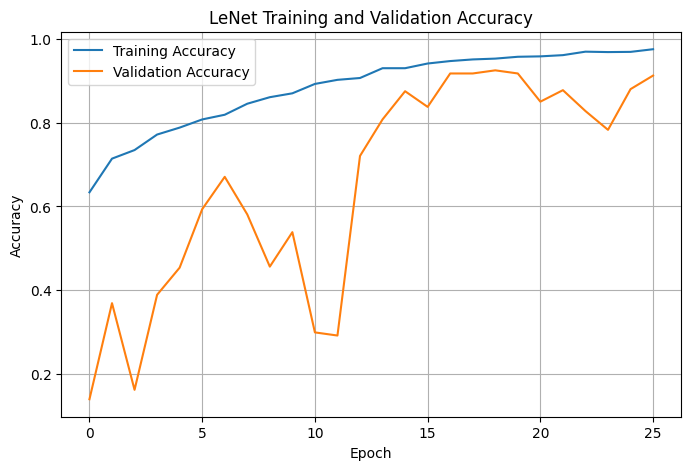

In [104]:
# ============================================================
# TRAINING / VALIDATION CURVES
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history_lenet.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_lenet.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LeNet Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

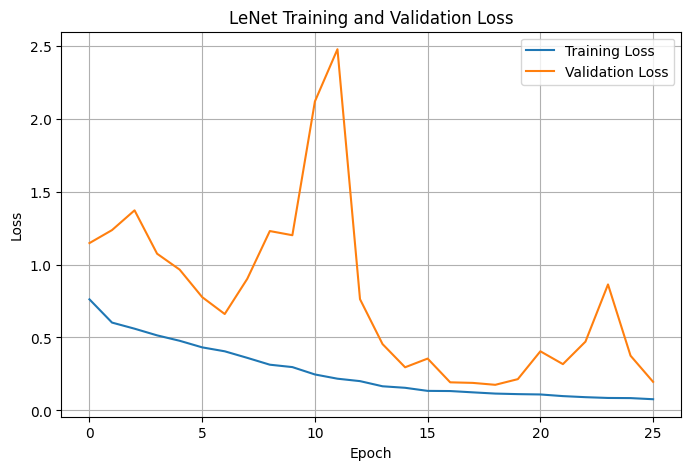

In [105]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_lenet.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_lenet.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LeNet Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [106]:
# ============================================================
# LOAD BEST MODEL
# ============================================================

best_lenet = keras.models.load_model(
    "results/cnn_models/best_lenet.keras"
)

print("Best LeNet checkpoint loaded successfully.")

Best LeNet checkpoint loaded successfully.


In [107]:
# ============================================================
# LENET TEST EVALUATION
# ============================================================

test_probabilities = best_lenet.predict(
    X_test_lenet,
    batch_size=BATCH_SIZE,
    verbose=1
)

test_predictions = np.argmax(
    test_probabilities,
    axis=1
)

accuracy = accuracy_score(
    y_test_cnn,
    test_predictions
)

macro_precision = precision_score(
    y_test_cnn,
    test_predictions,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    y_test_cnn,
    test_predictions,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    y_test_cnn,
    test_predictions,
    average="macro",
    zero_division=0
)

print("\n" + "=" * 60)
print("LENET FINAL TEST RESULTS")
print("=" * 60)

print(f"Accuracy        : {accuracy:.4f}")
print(f"Macro Precision : {macro_precision:.4f}")
print(f"Macro Recall    : {macro_recall:.4f}")
print(f"Macro F1        : {macro_f1:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 93ms/step

LENET FINAL TEST RESULTS
Accuracy        : 0.8954
Macro Precision : 0.8775
Macro Recall    : 0.8535
Macro F1        : 0.8637


In [108]:
# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print("\nLeNet Classification Report:\n")

print(
    classification_report(
        y_test_cnn,
        test_predictions,
        digits=4,
        zero_division=0
    )
)


LeNet Classification Report:

              precision    recall  f1-score   support

           0     0.8072    0.6837    0.7403        98
           1     0.8859    0.9167    0.9010       288
           2     0.9394    0.9602    0.9497       226

    accuracy                         0.8954       612
   macro avg     0.8775    0.8535    0.8637       612
weighted avg     0.8931    0.8954    0.8933       612



In [109]:
# ============================================================
# CONFUSION MATRIX
# ============================================================

cm_lenet = confusion_matrix(
    y_test_cnn,
    test_predictions
)

print("LeNet Confusion Matrix:")
print(cm_lenet)

LeNet Confusion Matrix:
[[ 67  29   2]
 [ 12 264  12]
 [  4   5 217]]


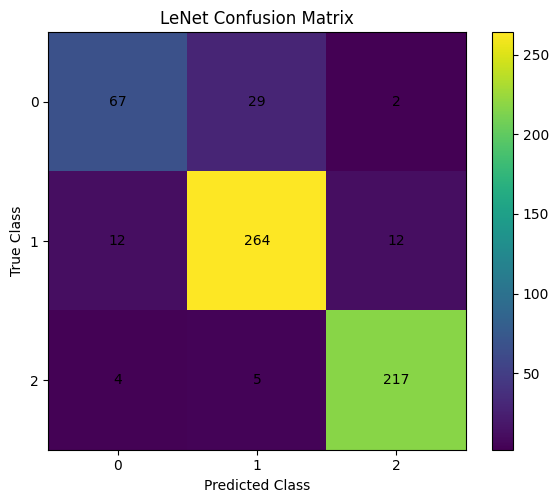

In [110]:
plt.figure(figsize=(6, 5))

plt.imshow(
    cm_lenet,
    interpolation="nearest"
)

plt.title("LeNet Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.colorbar()

plt.xticks(
    range(NUM_CLASSES),
    range(NUM_CLASSES)
)

plt.yticks(
    range(NUM_CLASSES),
    range(NUM_CLASSES)
)

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):

        plt.text(
            j,
            i,
            cm_lenet[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [111]:
# ============================================================
# PREDICTION DISTRIBUTION
# ============================================================

unique_predictions, prediction_counts = np.unique(
    test_predictions,
    return_counts=True
)

print("Prediction distribution:")

for cls, count in zip(
    unique_predictions,
    prediction_counts
):
    print(
        f"Class {cls}: {count}"
    )

Prediction distribution:
Class 0: 83
Class 1: 298
Class 2: 231


In [112]:
# ============================================================
# SAVE RESULTS
# ============================================================

lenet_result = {
    "Model": "LeNet",
    "Accuracy": accuracy,
    "Macro Precision": macro_precision,
    "Macro Recall": macro_recall,
    "Macro F1": macro_f1
}

lenet_result_df = pd.DataFrame(
    [lenet_result]
)

lenet_result_df

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,LeNet,0.895425,0.87751,0.853506,0.863676


In [113]:
#Alex Net
# ============================================================
# ALEXNET | PROFESSIONAL ADAPTED IMPLEMENTATION
# ============================================================

def build_alexnet():

    inputs = keras.Input(
        shape=(IMG_SIZE, IMG_SIZE, 3),
        name="image_input"
    )

    # --------------------------------------------------------
    # Block 1
    # --------------------------------------------------------

    x = layers.Conv2D(
        filters=64,
        kernel_size=(11, 11),
        strides=(2, 2),
        padding="same",
        activation="relu",
        name="alex_conv1"
    )(inputs)

    x = layers.BatchNormalization(
        name="alex_bn1"
    )(x)

    x = layers.MaxPooling2D(
        pool_size=(3, 3),
        strides=(2, 2),
        name="alex_pool1"
    )(x)

    # --------------------------------------------------------
    # Block 2
    # --------------------------------------------------------

    x = layers.Conv2D(
        filters=192,
        kernel_size=(5, 5),
        padding="same",
        activation="relu",
        name="alex_conv2"
    )(x)

    x = layers.BatchNormalization(
        name="alex_bn2"
    )(x)

    x = layers.MaxPooling2D(
        pool_size=(3, 3),
        strides=(2, 2),
        name="alex_pool2"
    )(x)

    # --------------------------------------------------------
    # Block 3
    # --------------------------------------------------------

    x = layers.Conv2D(
        filters=384,
        kernel_size=(3, 3),
        padding="same",
        activation="relu",
        name="alex_conv3"
    )(x)

    # --------------------------------------------------------
    # Block 4
    # --------------------------------------------------------

    x = layers.Conv2D(
        filters=256,
        kernel_size=(3, 3),
        padding="same",
        activation="relu",
        name="alex_conv4"
    )(x)

    # --------------------------------------------------------
    # Block 5
    # --------------------------------------------------------

    x = layers.Conv2D(
        filters=256,
        kernel_size=(3, 3),
        padding="same",
        activation="relu",
        name="alex_conv5"
    )(x)

    x = layers.MaxPooling2D(
        pool_size=(3, 3),
        strides=(2, 2),
        name="alex_pool3"
    )(x)

    # --------------------------------------------------------
    # Classification Head
    # --------------------------------------------------------

    x = layers.GlobalAveragePooling2D(
        name="global_average_pooling"
    )(x)

    x = layers.Dense(
        512,
        activation="relu",
        name="alex_dense1"
    )(x)

    x = layers.Dropout(
        0.50,
        name="alex_dropout1"
    )(x)

    x = layers.Dense(
        256,
        activation="relu",
        name="alex_dense2"
    )(x)

    x = layers.Dropout(
        0.40,
        name="alex_dropout2"
    )(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        name="classifier"
    )(x)

    model = keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="AlexNet_MRI_Classifier"
    )

    return model

In [114]:
# ============================================================
# CREATE ALEXNET
# ============================================================

alexnet_model = build_alexnet()

alexnet_model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=1e-3
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

alexnet_model.summary()

Model: "AlexNet_MRI_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_input (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ alex_conv1 (Conv2D)             │ (None, 64, 64, 64)     │        23,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ alex_bn1 (BatchNormalization)   │ (None, 64, 64, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ alex_pool1 (MaxPooling2D)       │ (None, 31, 31, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ alex_conv2 (Conv2D)             │ (None, 31, 31, 192)    │       307,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ alex_bn2 (BatchNormalization)   │ (None, 31, 31, 192)    │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ alex_pool2 (MaxPooling2D)       │ (None, 15, 15, 192)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ alex_conv3 (Conv2D)             │ (None, 15, 15, 384)    │       663,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ alex_conv4 (Conv2D)             │ (None, 15, 15, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ alex_conv5 (Conv2D)             │ (None, 15, 15, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ alex_pool3 (MaxPooling2D)       │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ alex_dense1 (Dense)             │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ alex_dropout1 (Dropout)         │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ alex_dense2 (Dense)             │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ alex_dropout2 (Dropout)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,734,403 (10.43 MB)

 Trainable params: 2,733,891 (10.43 MB)

 Non-trainable params: 512 (2.00 KB)

In [115]:
# ============================================================
# CLASS WEIGHTS
# ============================================================

alexnet_class_weights = lenet_class_weights

print("AlexNet class weights:")
print(alexnet_class_weights)

AlexNet class weights:
{0: 1.2340553549939832, 1: 0.687793427230047, 2: 1.3591782637508283}


In [116]:
# ============================================================
# ALEXNET CALLBACKS
# ============================================================

alexnet_callbacks = [

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),

    keras.callbacks.ModelCheckpoint(
        filepath="results/cnn_models/best_alexnet.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

In [117]:
# ============================================================
# TRAIN ALEXNET
# ============================================================

history_alexnet = alexnet_model.fit(

    X_train_lenet,
    y_train_cnn,

    validation_data=(
        X_val_lenet,
        y_val_cnn
    ),

    epochs=50,

    batch_size=BATCH_SIZE,

    class_weight=alexnet_class_weights,

    callbacks=alexnet_callbacks,

    verbose=1
)

Epoch 1/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 786ms/step - accuracy: 0.5061 - loss: 0.9799
Epoch 1: val_loss improved from None to 1.56276, saving model to results/cnn_models/best_alexnet.keras

Epoch 1: finished saving model to results/cnn_models/best_alexnet.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 61s 845ms/step - accuracy: 0.5061 - loss: 0.9799 - val_accuracy: 0.5012 - val_loss: 1.5628 - learning_rate: 0.0010
Epoch 2/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 795ms/step - accuracy: 0.5982 - loss: 0.7659
Epoch 2: val_loss improved from 1.56276 to 0.92244, saving model to results/cnn_models/best_alexnet.keras

Epoch 2: finished saving model to results/cnn_models/best_alexnet.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 55s 849ms/step - accuracy: 0.5982 - loss: 0.7659 - val_accuracy: 0.6135 - val_loss: 0.9224 - learning_rate: 0.0010
Epoch 3/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 788ms/step - accuracy: 0.6533 - loss: 0.6734
Epoch 3: val_loss improved from 0.92244 to 0.56317, saving model to results/cnn_models/best_alexnet.ker

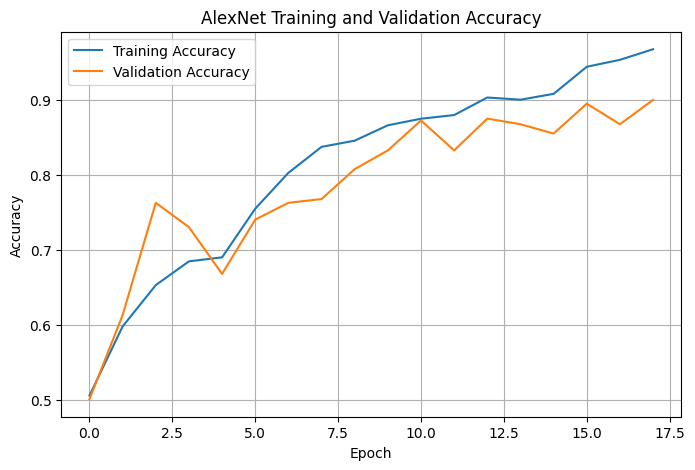

In [118]:
# ============================================================
# ALEXNET ACCURACY CURVE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history_alexnet.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_alexnet.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("AlexNet Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

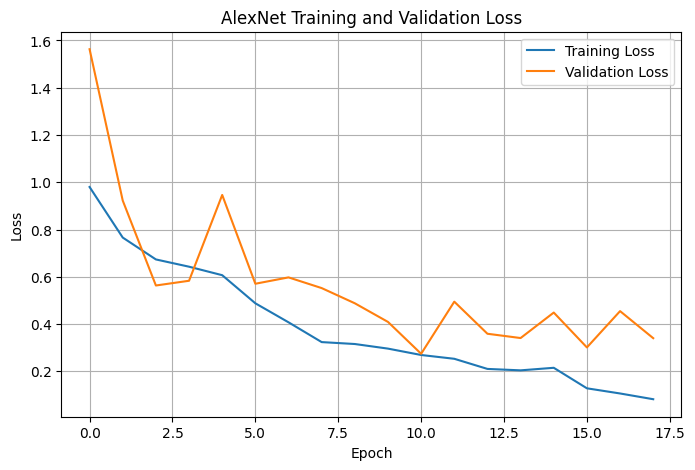

In [119]:
# ============================================================
# ALEXNET LOSS CURVE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history_alexnet.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_alexnet.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("AlexNet Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [120]:
# ============================================================
# LOAD BEST ALEXNET
# ============================================================

best_alexnet = keras.models.load_model(
    "results/cnn_models/best_alexnet.keras"
)

print("Best AlexNet checkpoint loaded successfully.")

Best AlexNet checkpoint loaded successfully.


In [121]:
# ============================================================
# ALEXNET FINAL TEST EVALUATION
# ============================================================

alexnet_probabilities = best_alexnet.predict(
    X_test_lenet,
    batch_size=BATCH_SIZE,
    verbose=1
)

alexnet_predictions = np.argmax(
    alexnet_probabilities,
    axis=1
)

alexnet_accuracy = accuracy_score(
    y_test_cnn,
    alexnet_predictions
)

alexnet_precision = precision_score(
    y_test_cnn,
    alexnet_predictions,
    average="macro",
    zero_division=0
)

alexnet_recall = recall_score(
    y_test_cnn,
    alexnet_predictions,
    average="macro",
    zero_division=0
)

alexnet_f1 = f1_score(
    y_test_cnn,
    alexnet_predictions,
    average="macro",
    zero_division=0
)

print("\n" + "=" * 65)
print("ALEXNET FINAL TEST RESULTS")
print("=" * 65)

print(f"Accuracy        : {alexnet_accuracy:.4f}")
print(f"Macro Precision : {alexnet_precision:.4f}")
print(f"Macro Recall    : {alexnet_recall:.4f}")
print(f"Macro F1        : {alexnet_f1:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 235ms/step

ALEXNET FINAL TEST RESULTS
Accuracy        : 0.8137
Macro Precision : 0.7871
Macro Recall    : 0.8367
Macro F1        : 0.7949


In [122]:
# ============================================================
# ALEXNET CLASSIFICATION REPORT
# ============================================================

print("\nAlexNet Classification Report:\n")

print(
    classification_report(
        y_test_cnn,
        alexnet_predictions,
        digits=4,
        zero_division=0
    )
)


AlexNet Classification Report:

              precision    recall  f1-score   support

           0     0.5506    0.8878    0.6797        98
           1     0.9075    0.7153    0.8000       288
           2     0.9031    0.9071    0.9051       226

    accuracy                         0.8137       612
   macro avg     0.7871    0.8367    0.7949       612
weighted avg     0.8487    0.8137    0.8195       612



In [123]:
# ============================================================
# ALEXNET CONFUSION MATRIX
# ============================================================

cm_alexnet = confusion_matrix(
    y_test_cnn,
    alexnet_predictions
)

print("AlexNet Confusion Matrix:")
print(cm_alexnet)

AlexNet Confusion Matrix:
[[ 87   6   5]
 [ 65 206  17]
 [  6  15 205]]


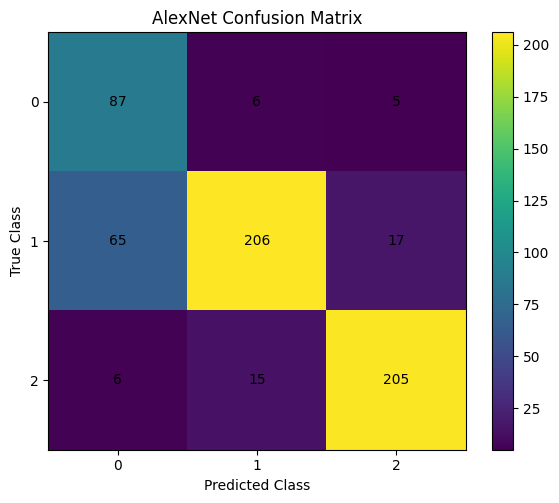

In [124]:
plt.figure(figsize=(6, 5))

plt.imshow(
    cm_alexnet,
    interpolation="nearest"
)

plt.title("AlexNet Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.colorbar()

plt.xticks(
    range(NUM_CLASSES),
    range(NUM_CLASSES)
)

plt.yticks(
    range(NUM_CLASSES),
    range(NUM_CLASSES)
)

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):

        plt.text(
            j,
            i,
            cm_alexnet[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [125]:
# ============================================================
# ALEXNET PREDICTION DISTRIBUTION
# ============================================================

unique_predictions, prediction_counts = np.unique(
    alexnet_predictions,
    return_counts=True
)

print("AlexNet Prediction Distribution:")

for cls, count in zip(
    unique_predictions,
    prediction_counts
):
    print(
        f"Class {cls}: {count}"
    )

AlexNet Prediction Distribution:
Class 0: 158
Class 1: 227
Class 2: 227


In [126]:
# ============================================================
# ALEXNET RESULT
# ============================================================

alexnet_result = {
    "Model": "AlexNet",
    "Accuracy": alexnet_accuracy,
    "Macro Precision": alexnet_precision,
    "Macro Recall": alexnet_recall,
    "Macro F1": alexnet_f1
}

alexnet_result_df = pd.DataFrame(
    [alexnet_result]
)

alexnet_result_df

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,AlexNet,0.813725,0.787069,0.836704,0.794922


In [127]:
#VGG16
# ============================================================
# VGG16 | PROFESSIONAL TRANSFER LEARNING IMPLEMENTATION
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import VGG16

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

SEED = 42

np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = 128
NUM_CLASSES = 3
BATCH_SIZE = 32

os.makedirs("results/transfer_models", exist_ok=True)

print("TensorFlow:", tf.__version__)
print("VGG16 input:", (IMG_SIZE, IMG_SIZE, 3))

TensorFlow: 2.21.0
VGG16 input: (128, 128, 3)


In [128]:
# ============================================================
# VERIFY TRANSFER LEARNING DATA
# ============================================================

print("Train:", X_train_tl.shape)
print("Validation:", X_val_tl.shape)
print("Test:", X_test_tl.shape)

print("\nPixel range:")
print("Train:", X_train_tl.min(), X_train_tl.max())
print("Val  :", X_val_tl.min(), X_val_tl.max())
print("Test :", X_test_tl.min(), X_test_tl.max())

Train: (2051, 128, 128, 3)
Validation: (401, 128, 128, 3)
Test: (612, 128, 128, 3)

Pixel range:
Train: 0.0 1.0
Val  : 0.0 1.0
Test : 0.0 1.0


In [129]:
# ============================================================
# VGG16 PREPROCESSING
# ============================================================

X_train_vgg16 = X_train_tl.astype("float32")
X_val_vgg16   = X_val_tl.astype("float32")
X_test_vgg16  = X_test_tl.astype("float32")

if X_train_vgg16.max() <= 1.0:

    X_train_vgg16 *= 255.0
    X_val_vgg16   *= 255.0
    X_test_vgg16  *= 255.0

# VGG16-specific preprocessing
from tensorflow.keras.applications.vgg16 import preprocess_input

X_train_vgg16 = preprocess_input(X_train_vgg16)
X_val_vgg16   = preprocess_input(X_val_vgg16)
X_test_vgg16  = preprocess_input(X_test_vgg16)

print("VGG16 preprocessing completed.")
print(X_train_vgg16.shape)

VGG16 preprocessing completed.
(2051, 128, 128, 3)


In [130]:
# ============================================================
# CLASS WEIGHTS
# ============================================================

from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train_cnn)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_cnn
)

vgg16_class_weights = {
    int(c): float(w)
    for c, w in zip(classes, weights)
}

print("VGG16 class weights:")
print(vgg16_class_weights)

VGG16 class weights:
{0: 1.2340553549939832, 1: 0.687793427230047, 2: 1.3591782637508283}


In [131]:
# ============================================================
# VGG16 MODEL
# ============================================================

def build_vgg16():

    inputs = keras.Input(
        shape=(IMG_SIZE, IMG_SIZE, 3),
        name="vgg16_input"
    )

    # --------------------------------------------------------
    # Pretrained VGG16 backbone
    # --------------------------------------------------------

    base_model = VGG16(
        include_top=False,
        weights="imagenet",
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )

    base_model.trainable = False

    x = base_model(
        inputs,
        training=False
    )

    # --------------------------------------------------------
    # Classification head
    # --------------------------------------------------------

    x = layers.GlobalAveragePooling2D(
        name="global_average_pooling"
    )(x)

    x = layers.Dense(
        512,
        activation="relu",
        name="dense_512"
    )(x)

    x = layers.BatchNormalization(
        name="batch_norm"
    )(x)

    x = layers.Dropout(
        0.5,
        name="dropout"
    )(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        name="classifier"
    )(x)

    model = keras.Model(
        inputs,
        outputs,
        name="VGG16_MRI_Classifier"
    )

    return model, base_model

In [132]:
# ============================================================
# CREATE VGG16
# ============================================================

vgg16_model, vgg16_base = build_vgg16()

vgg16_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

vgg16_model.summary()

Model: "VGG16_MRI_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16_input (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_512 (Dense)               │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm (BatchNormalization) │ (None, 512)            │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 3)              │         1,539 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,980,931 (57.15 MB)

 Trainable params: 265,219 (1.01 MB)

 Non-trainable params: 14,715,712 (56.14 MB)

In [133]:
# ============================================================
# TRAINABLE PARAMETER CHECK
# ============================================================

trainable_params = np.sum([
    np.prod(v.shape)
    for v in vgg16_model.trainable_weights
])

non_trainable_params = np.sum([
    np.prod(v.shape)
    for v in vgg16_model.non_trainable_weights
])

print("Trainable parameters:", trainable_params)
print("Non-trainable parameters:", non_trainable_params)

Trainable parameters: 265219
Non-trainable parameters: 14715712


In [134]:
# ============================================================
# VGG16 CALLBACKS
# ============================================================

vgg16_callbacks = [

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),

    keras.callbacks.ModelCheckpoint(
        "results/transfer_models/best_vgg16_stage1.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

In [135]:
# ============================================================
# VGG16 STAGE 1 — FROZEN BACKBONE
# ============================================================

history_vgg16_stage1 = vgg16_model.fit(

    X_train_vgg16,
    y_train_cnn,

    validation_data=(
        X_val_vgg16,
        y_val_cnn
    ),

    epochs=20,

    batch_size=BATCH_SIZE,

    class_weight=vgg16_class_weights,

    callbacks=vgg16_callbacks,

    verbose=1
)

Epoch 1/20
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5524 - loss: 1.3127
Epoch 1: val_loss improved from None to 0.52706, saving model to results/transfer_models/best_vgg16_stage1.keras

Epoch 1: finished saving model to results/transfer_models/best_vgg16_stage1.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 96s 1s/step - accuracy: 0.5524 - loss: 1.3127 - val_accuracy: 0.8254 - val_loss: 0.5271 - learning_rate: 1.0000e-04
Epoch 2/20
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7084 - loss: 0.7662
Epoch 2: val_loss improved from 0.52706 to 0.45208, saving model to results/transfer_models/best_vgg16_stage1.keras

Epoch 2: finished saving model to results/transfer_models/best_vgg16_stage1.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 83s 1s/step - accuracy: 0.7084 - loss: 0.7662 - val_accuracy: 0.8404 - val_loss: 0.4521 - learning_rate: 1.0000e-04
Epoch 3/20
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7445 - loss: 0.6724
Epoch 3: val_loss improved from 0.45208 to 0.44152, saving model to re

In [136]:
# ============================================================
# VGG16 STAGE 2 — FINE TUNING
# ============================================================

vgg16_base.trainable = True

# Freeze earlier layers
for layer in vgg16_base.layers[:-8]:
    layer.trainable = False

# Keep last 8 layers trainable
for layer in vgg16_base.layers[-8:]:
    layer.trainable = True

print("Trainable VGG16 layers:")

for layer in vgg16_base.layers:
    if layer.trainable:
        print(layer.name)

Trainable VGG16 layers:
block4_conv1
block4_conv2
block4_conv3
block4_pool
block5_conv1
block5_conv2
block5_conv3
block5_pool


In [137]:
# ============================================================
# VGG16 FINE-TUNING COMPILE
# ============================================================

vgg16_model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=1e-5
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

print("VGG16 recompiled for fine-tuning.")

VGG16 recompiled for fine-tuning.


In [138]:
# ============================================================
# FINE-TUNING CALLBACKS
# ============================================================

vgg16_ft_callbacks = [

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-8,
        verbose=1
    ),

    keras.callbacks.ModelCheckpoint(
        "results/transfer_models/best_vgg16_finetuned.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

In [139]:
# ============================================================
# VGG16 FINE-TUNING
# ============================================================

history_vgg16_ft = vgg16_model.fit(

    X_train_vgg16,
    y_train_cnn,

    validation_data=(
        X_val_vgg16,
        y_val_cnn
    ),

    epochs=15,

    batch_size=BATCH_SIZE,

    class_weight=vgg16_class_weights,

    callbacks=vgg16_ft_callbacks,

    verbose=1
)

Epoch 1/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 43s/step - accuracy: 0.8737 - loss: 0.3276 
Epoch 1: val_loss improved from None to 0.44190, saving model to results/transfer_models/best_vgg16_finetuned.keras

Epoch 1: finished saving model to results/transfer_models/best_vgg16_finetuned.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 2758s 43s/step - accuracy: 0.8737 - loss: 0.3276 - val_accuracy: 0.8229 - val_loss: 0.4419 - learning_rate: 1.0000e-05
Epoch 2/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8976 - loss: 0.2467
Epoch 2: val_loss improved from 0.44190 to 0.20024, saving model to results/transfer_models/best_vgg16_finetuned.keras

Epoch 2: finished saving model to results/transfer_models/best_vgg16_finetuned.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 170s 3s/step - accuracy: 0.8976 - loss: 0.2467 - val_accuracy: 0.9302 - val_loss: 0.2002 - learning_rate: 1.0000e-05
Epoch 3/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9342 - loss: 0.1637
Epoch 3: val_loss did not improve from 0.20024
65/65

In [140]:
# ============================================================
# LOAD BEST VGG16
# ============================================================

best_vgg16 = keras.models.load_model(
    "results/transfer_models/best_vgg16_finetuned.keras"
)

print("Best VGG16 fine-tuned model loaded.")

Best VGG16 fine-tuned model loaded.


In [141]:
# ============================================================
# VGG16 TEST PREDICTIONS
# ============================================================

vgg16_probabilities = best_vgg16.predict(
    X_test_vgg16,
    batch_size=BATCH_SIZE,
    verbose=1
)

vgg16_predictions = np.argmax(
    vgg16_probabilities,
    axis=1
)

print(
    "Prediction distribution:",
    np.unique(
        vgg16_predictions,
        return_counts=True
    )
)

20/20 ━━━━━━━━━━━━━━━━━━━━ 27s 1s/step
Prediction distribution: (array([0, 1, 2], dtype=int64), array([127, 279, 206], dtype=int64))


In [142]:
# ============================================================
# VGG16 FINAL METRICS
# ============================================================

vgg16_accuracy = accuracy_score(
    y_test_cnn,
    vgg16_predictions
)

vgg16_precision = precision_score(
    y_test_cnn,
    vgg16_predictions,
    average="macro",
    zero_division=0
)

vgg16_recall = recall_score(
    y_test_cnn,
    vgg16_predictions,
    average="macro",
    zero_division=0
)

vgg16_f1 = f1_score(
    y_test_cnn,
    vgg16_predictions,
    average="macro",
    zero_division=0
)

print("\n" + "=" * 65)
print("VGG16 FINAL TEST RESULTS")
print("=" * 65)

print(f"Accuracy        : {vgg16_accuracy:.4f}")
print(f"Macro Precision : {vgg16_precision:.4f}")
print(f"Macro Recall    : {vgg16_recall:.4f}")
print(f"Macro F1        : {vgg16_f1:.4f}")


VGG16 FINAL TEST RESULTS
Accuracy        : 0.9101
Macro Precision : 0.8752
Macro Recall    : 0.9027
Macro F1        : 0.8839


In [143]:
# ============================================================
# VGG16 CLASSIFICATION REPORT
# ============================================================

print("\nVGG16 Classification Report:\n")

print(
    classification_report(
        y_test_cnn,
        vgg16_predictions,
        digits=4,
        zero_division=0
    )
)


VGG16 Classification Report:

              precision    recall  f1-score   support

           0     0.6772    0.8776    0.7644        98
           1     0.9534    0.9236    0.9383       288
           2     0.9951    0.9071    0.9491       226

    accuracy                         0.9101       612
   macro avg     0.8752    0.9027    0.8839       612
weighted avg     0.9246    0.9101    0.9144       612



In [144]:
# ============================================================
# VGG16 CONFUSION MATRIX
# ============================================================

cm_vgg16 = confusion_matrix(
    y_test_cnn,
    vgg16_predictions
)

print("VGG16 Confusion Matrix:")
print(cm_vgg16)

VGG16 Confusion Matrix:
[[ 86  11   1]
 [ 22 266   0]
 [ 19   2 205]]


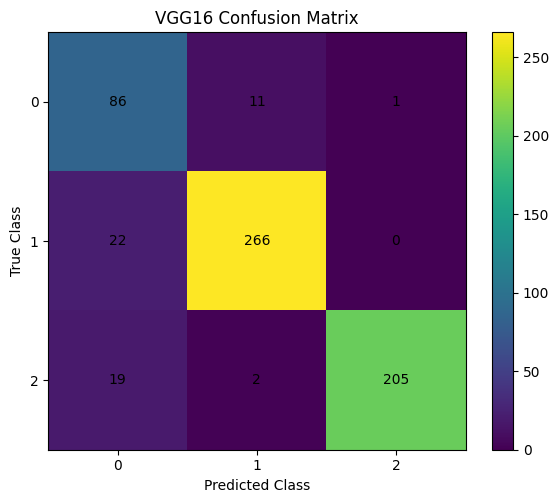

In [145]:
plt.figure(figsize=(6, 5))

plt.imshow(
    cm_vgg16,
    interpolation="nearest"
)

plt.title("VGG16 Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.colorbar()

plt.xticks(
    range(NUM_CLASSES),
    range(NUM_CLASSES)
)

plt.yticks(
    range(NUM_CLASSES),
    range(NUM_CLASSES)
)

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):

        plt.text(
            j,
            i,
            cm_vgg16[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [146]:
# ============================================================
# VGG16 RESULT RECORD
# ============================================================

vgg16_result = {
    "Model": "VGG16",
    "Accuracy": vgg16_accuracy,
    "Macro Precision": vgg16_precision,
    "Macro Recall": vgg16_recall,
    "Macro F1": vgg16_f1
}

vgg16_result_df = pd.DataFrame(
    [vgg16_result]
)

vgg16_result_df

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,VGG16,0.910131,0.875239,0.902747,0.88393


In [147]:
# ============================================================
# VGG19 | PROFESSIONAL TRANSFER LEARNING IMPLEMENTATION
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import VGG19
from tensorflow.keras.applications.vgg19 import preprocess_input

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

SEED = 42

np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = 128
NUM_CLASSES = 3
BATCH_SIZE = 32

os.makedirs("results/transfer_models", exist_ok=True)

print("TensorFlow:", tf.__version__)
print("VGG19 input:", (IMG_SIZE, IMG_SIZE, 3))

TensorFlow: 2.21.0
VGG19 input: (128, 128, 3)


In [148]:
# ============================================================
# VGG19 DATA PREPARATION
# ============================================================

X_train_vgg19 = X_train_tl.astype("float32")
X_val_vgg19   = X_val_tl.astype("float32")
X_test_vgg19  = X_test_tl.astype("float32")

print("Original range:")
print(
    X_train_vgg19.min(),
    X_train_vgg19.max()
)

# Convert [0,1] → [0,255] if necessary
if X_train_vgg19.max() <= 1.0:

    X_train_vgg19 *= 255.0
    X_val_vgg19   *= 255.0
    X_test_vgg19  *= 255.0

# VGG19-specific preprocessing
X_train_vgg19 = preprocess_input(X_train_vgg19)
X_val_vgg19   = preprocess_input(X_val_vgg19)
X_test_vgg19  = preprocess_input(X_test_vgg19)

print("\nPrepared shapes:")
print("Train:", X_train_vgg19.shape)
print("Val  :", X_val_vgg19.shape)
print("Test :", X_test_vgg19.shape)

Original range:
0.0 1.0

Prepared shapes:
Train: (2051, 128, 128, 3)
Val  : (401, 128, 128, 3)
Test : (612, 128, 128, 3)


In [149]:
# ============================================================
# CLASS WEIGHTS
# ============================================================

vgg19_class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(
        classes,
        weights
    )
}

print("VGG19 class weights:")
print(vgg19_class_weights)

VGG19 class weights:
{0: 1.2340553549939832, 1: 0.687793427230047, 2: 1.3591782637508283}


In [150]:
from sklearn.utils.class_weight import compute_class_weight

classes_vgg19 = np.unique(y_train_cnn)

weights_vgg19 = compute_class_weight(
    class_weight="balanced",
    classes=classes_vgg19,
    y=y_train_cnn
)

vgg19_class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(
        classes_vgg19,
        weights_vgg19
    )
}

print(vgg19_class_weights)

{0: 1.2340553549939832, 1: 0.687793427230047, 2: 1.3591782637508283}


In [151]:
# ============================================================
# VGG19 MODEL
# ============================================================

def build_vgg19():

    inputs = keras.Input(
        shape=(IMG_SIZE, IMG_SIZE, 3),
        name="vgg19_input"
    )

    # --------------------------------------------------------
    # Pretrained VGG19 backbone
    # --------------------------------------------------------

    base_model = VGG19(
        include_top=False,
        weights="imagenet",
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )

    # Stage 1: freeze pretrained backbone
    base_model.trainable = False

    x = base_model(
        inputs,
        training=False
    )

    # --------------------------------------------------------
    # Custom classification head
    # --------------------------------------------------------

    x = layers.GlobalAveragePooling2D(
        name="global_average_pooling"
    )(x)

    x = layers.Dense(
        512,
        activation="relu",
        name="dense_512"
    )(x)

    x = layers.BatchNormalization(
        name="batch_normalization"
    )(x)

    x = layers.Dropout(
        0.50,
        name="dropout_1"
    )(x)

    x = layers.Dense(
        256,
        activation="relu",
        name="dense_256"
    )(x)

    x = layers.Dropout(
        0.30,
        name="dropout_2"
    )(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        name="classifier"
    )(x)

    model = keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="VGG19_MRI_Classifier"
    )

    return model, base_model

In [152]:
# ============================================================
# CREATE VGG19
# ============================================================

vgg19_model, vgg19_base = build_vgg19()

vgg19_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

vgg19_model.summary()

Model: "VGG19_MRI_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg19_input (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg19 (Functional)              │ (None, 4, 4, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_512 (Dense)               │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_256 (Dense)               │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,421,187 (77.90 MB)

 Trainable params: 395,779 (1.51 MB)

 Non-trainable params: 20,025,408 (76.39 MB)

In [153]:
# ============================================================
# PARAMETER ANALYSIS
# ============================================================

trainable_params = np.sum([
    np.prod(v.shape)
    for v in vgg19_model.trainable_weights
])

non_trainable_params = np.sum([
    np.prod(v.shape)
    for v in vgg19_model.non_trainable_weights
])

print("Trainable parameters:", trainable_params)
print("Non-trainable parameters:", non_trainable_params)

Trainable parameters: 395779
Non-trainable parameters: 20025408


In [154]:
# ============================================================
# VGG19 STAGE-1 CALLBACKS
# ============================================================

vgg19_callbacks = [

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),

    keras.callbacks.ModelCheckpoint(
        filepath=
        "results/transfer_models/best_vgg19_stage1.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

In [155]:
# ============================================================
# VGG19 STAGE 1 — TRANSFER LEARNING
# ============================================================

history_vgg19_stage1 = vgg19_model.fit(

    X_train_vgg19,
    y_train_cnn,

    validation_data=(
        X_val_vgg19,
        y_val_cnn
    ),

    epochs=20,

    batch_size=BATCH_SIZE,

    class_weight=vgg19_class_weights,

    callbacks=vgg19_callbacks,

    verbose=1
)

Epoch 1/20
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.4773 - loss: 1.2997
Epoch 1: val_loss improved from None to 0.67168, saving model to results/transfer_models/best_vgg19_stage1.keras

Epoch 1: finished saving model to results/transfer_models/best_vgg19_stage1.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 125s 2s/step - accuracy: 0.4773 - loss: 1.2997 - val_accuracy: 0.7182 - val_loss: 0.6717 - learning_rate: 1.0000e-04
Epoch 2/20
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6368 - loss: 0.8757
Epoch 2: val_loss improved from 0.67168 to 0.49138, saving model to results/transfer_models/best_vgg19_stage1.keras

Epoch 2: finished saving model to results/transfer_models/best_vgg19_stage1.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 117s 2s/step - accuracy: 0.6368 - loss: 0.8757 - val_accuracy: 0.8080 - val_loss: 0.4914 - learning_rate: 1.0000e-04
Epoch 3/20
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7123 - loss: 0.7024
Epoch 3: val_loss improved from 0.49138 to 0.44399, saving model to 

In [156]:
# ============================================================
# VGG19 FINE-TUNING
# ============================================================

vgg19_base.trainable = True

# Freeze earlier layers
for layer in vgg19_base.layers[:-8]:
    layer.trainable = False

# Unfreeze final 8 layers
for layer in vgg19_base.layers[-8:]:
    layer.trainable = True

print("Trainable VGG19 layers:\n")

for layer in vgg19_base.layers:

    if layer.trainable:
        print(layer.name)

Trainable VGG19 layers:

block4_conv3
block4_conv4
block4_pool
block5_conv1
block5_conv2
block5_conv3
block5_conv4
block5_pool


In [157]:
# ============================================================
# RECOMPILE FOR FINE-TUNING
# ============================================================

vgg19_model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=1e-5
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

print("VGG19 recompiled for fine-tuning.")

VGG19 recompiled for fine-tuning.


In [158]:
# ============================================================
# VGG19 FINE-TUNING CALLBACKS
# ============================================================

vgg19_ft_callbacks = [

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-8,
        verbose=1
    ),

    keras.callbacks.ModelCheckpoint(
        filepath=
        "results/transfer_models/best_vgg19_finetuned.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

In [159]:
# ============================================================
# VGG19 FINE-TUNING
# ============================================================

history_vgg19_ft = vgg19_model.fit(

    X_train_vgg19,
    y_train_cnn,

    validation_data=(
        X_val_vgg19,
        y_val_cnn
    ),

    epochs=15,

    batch_size=BATCH_SIZE,

    class_weight=vgg19_class_weights,

    callbacks=vgg19_ft_callbacks,

    verbose=1
)

Epoch 1/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8737 - loss: 0.3078
Epoch 1: val_loss improved from None to 0.29151, saving model to results/transfer_models/best_vgg19_finetuned.keras

Epoch 1: finished saving model to results/transfer_models/best_vgg19_finetuned.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 188s 3s/step - accuracy: 0.8737 - loss: 0.3078 - val_accuracy: 0.8903 - val_loss: 0.2915 - learning_rate: 1.0000e-05
Epoch 2/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9108 - loss: 0.2288
Epoch 2: val_loss improved from 0.29151 to 0.20047, saving model to results/transfer_models/best_vgg19_finetuned.keras

Epoch 2: finished saving model to results/transfer_models/best_vgg19_finetuned.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 177s 3s/step - accuracy: 0.9108 - loss: 0.2288 - val_accuracy: 0.9152 - val_loss: 0.2005 - learning_rate: 1.0000e-05
Epoch 3/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9313 - loss: 0.1688
Epoch 3: val_loss improved from 0.20047 to 0.16392, savi

In [160]:
# ============================================================
# LOAD BEST VGG19
# ============================================================

best_vgg19 = keras.models.load_model(
    "results/transfer_models/best_vgg19_finetuned.keras"
)

print("Best VGG19 fine-tuned model loaded successfully.")

Best VGG19 fine-tuned model loaded successfully.


In [161]:
# ============================================================
# VGG19 TEST PREDICTIONS
# ============================================================

vgg19_probabilities = best_vgg19.predict(
    X_test_vgg19,
    batch_size=BATCH_SIZE,
    verbose=1
)

vgg19_predictions = np.argmax(
    vgg19_probabilities,
    axis=1
)

print(
    "VGG19 Prediction Distribution:",
    np.unique(
        vgg19_predictions,
        return_counts=True
    )
)

20/20 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step
VGG19 Prediction Distribution: (array([0, 1, 2], dtype=int64), array([116, 279, 217], dtype=int64))


In [162]:
# ============================================================
# VGG19 FINAL METRICS
# ============================================================

vgg19_accuracy = accuracy_score(
    y_test_cnn,
    vgg19_predictions
)

vgg19_precision = precision_score(
    y_test_cnn,
    vgg19_predictions,
    average="macro",
    zero_division=0
)

vgg19_recall = recall_score(
    y_test_cnn,
    vgg19_predictions,
    average="macro",
    zero_division=0
)

vgg19_f1 = f1_score(
    y_test_cnn,
    vgg19_predictions,
    average="macro",
    zero_division=0
)

print("\n" + "=" * 65)
print("VGG19 FINAL TEST RESULTS")
print("=" * 65)

print(f"Accuracy        : {vgg19_accuracy:.4f}")
print(f"Macro Precision : {vgg19_precision:.4f}")
print(f"Macro Recall    : {vgg19_recall:.4f}")
print(f"Macro F1        : {vgg19_f1:.4f}")


VGG19 FINAL TEST RESULTS
Accuracy        : 0.9150
Macro Precision : 0.8798
Macro Recall    : 0.9001
Macro F1        : 0.8879


In [163]:
# ============================================================
# VGG19 CLASSIFICATION REPORT
# ============================================================

print("\nVGG19 Classification Report:\n")

print(
    classification_report(
        y_test_cnn,
        vgg19_predictions,
        digits=4,
        zero_division=0
    )
)


VGG19 Classification Report:

              precision    recall  f1-score   support

           0     0.7069    0.8367    0.7664        98
           1     0.9462    0.9167    0.9312       288
           2     0.9862    0.9469    0.9661       226

    accuracy                         0.9150       612
   macro avg     0.8798    0.9001    0.8879       612
weighted avg     0.9227    0.9150    0.9177       612



In [164]:
# ============================================================
# VGG19 CONFUSION MATRIX
# ============================================================

cm_vgg19 = confusion_matrix(
    y_test_cnn,
    vgg19_predictions
)

print("VGG19 Confusion Matrix:")
print(cm_vgg19)

VGG19 Confusion Matrix:
[[ 82  13   3]
 [ 24 264   0]
 [ 10   2 214]]


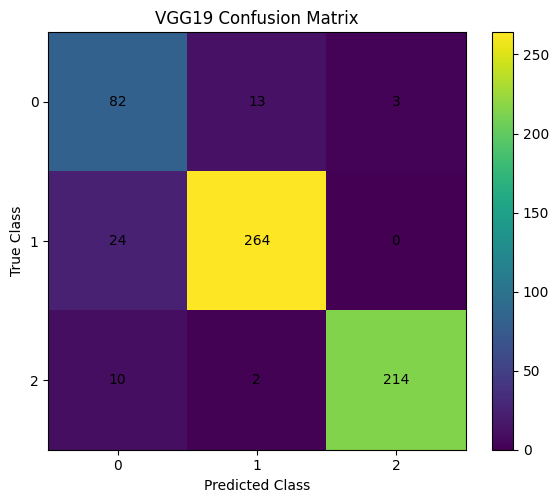

In [165]:
plt.figure(figsize=(6, 5))

plt.imshow(
    cm_vgg19,
    interpolation="nearest"
)

plt.title("VGG19 Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.colorbar()

plt.xticks(
    range(NUM_CLASSES),
    range(NUM_CLASSES)
)

plt.yticks(
    range(NUM_CLASSES),
    range(NUM_CLASSES)
)

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):

        plt.text(
            j,
            i,
            cm_vgg19[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [166]:
# ============================================================
# VGG19 RESULT RECORD
# ============================================================

vgg19_result = {
    "Model": "VGG19",
    "Accuracy": vgg19_accuracy,
    "Macro Precision": vgg19_precision,
    "Macro Recall": vgg19_recall,
    "Macro F1": vgg19_f1
}

vgg19_result_df = pd.DataFrame(
    [vgg19_result]
)

vgg19_result_df

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,VGG19,0.915033,0.879769,0.900101,0.887904
